# Clasificación de enfermedades en hojas de tomate con una Red Neuronal Convolucional (CNN)

**Asignatura:** TLY1102 — Técnicas Avanzadas de Machine Learning I
**Evaluación:** Parcial N°2 — Presentación y defensa técnica del proyecto
**Continuidad:** este notebook retoma el problema de la Evaluación Parcial N°1 (MLP sobre hojas de tomate de PlantVillage) y lo resuelve con una CNN, **con el mismo subconjunto de imágenes, la misma partición 70/15/15 y la misma semilla (1102)**. Así la diferencia entre MLP y CNN se debe a la arquitectura y no al azar del muestreo.

**Estructura del notebook (según la pauta):** a) Introducción → secciones 1–2 · b) Preparación de datos → 3 · c) Diseño de la CNN → 4 · d) Entrenamiento → 5 · e) Evaluación → 6 · f) Comparación MLP vs CNN → 7 · g) Feature Maps y mapas de activación → 8 · h) Análisis de resultados → 9 · i) Conclusiones → 10.

---

## Cómo ejecutarlo

### Opción A — en local, dentro del repositorio (recomendado)

```text
MLp/
├── data/PlantVillage/<clase>/*.jpg   ← o el zip en data/raw/PlantVillage.zip
├── models/                           ← artefactos de la EP1 (ya vienen en el repo)
├── images/                           ← figuras (se generan)
└── notebooks/plantvillage_cnn.ipynb  ← este notebook
```

Ejecutar todas las celdas. Las rutas se detectan solas (no hay que editar nada).

### Opción B — Google Colab (sin Google Drive)

1. **GPU (recomendado):** `Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU`. Funciona también sin GPU, solo más lento.
2. **Sube `PlantVillage.zip`** al panel de archivos de la sesión (ícono de carpeta, a la izquierda) y espera a que termine la subida.
3. `Entorno de ejecución → Ejecutar todas`. Los artefactos de la EP1 (partición, métricas y modelo del MLP) se descargan solos clonando el repositorio del grupo; si no hay internet, sube también `MLp-main.zip`.

> **Tiempo estimado:** 10–20 min con GPU; 25–50 min sin GPU (la sección 5.4, barrido de configuraciones, es lo más largo; se puede desactivar con `RUN_EXPERIMENTS = False`).
> **Resultados:** las figuras quedan en `images/` (prefijo `cnn_`) y el modelo y las métricas en `models/` (sufijo `_cnn`).


## 0. Configuración del entorno

In [1]:
# Solo se instala lo que falte (en Colab normalmente no falta nada).
import importlib.util

for paquete in ["tensorflow", "sklearn", "seaborn", "pandas", "matplotlib", "PIL", "scipy"]:
    if importlib.util.find_spec(paquete) is None:
        nombre_pip = {"sklearn": "scikit-learn", "PIL": "pillow"}.get(paquete, paquete)
        print(f"Instalando {nombre_pip}...")
        %pip install -q {nombre_pip}

In [2]:
import importlib.util
import os
import random
import re
import subprocess
import time
import warnings
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, SGD

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
)
from scipy.stats import binomtest

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# ---- Semilla única: la MISMA de la EP1 (variante del grupo) -----------------
SEED = 1102
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("Semilla fijada en:", SEED)
print("GPU disponible   :", [g.name for g in gpus] if gpus else "NO (se usará CPU)")
if not gpus:
    print("  Sugerencia: Entorno de ejecución → Cambiar tipo de entorno → T4 GPU")

TensorFlow: 2.21.0 | Keras: 3.15.1
Semilla fijada en: 1102
GPU disponible   : NO (se usará CPU)
  Sugerencia: Entorno de ejecución → Cambiar tipo de entorno → T4 GPU


In [3]:
# ---- Parámetros del proyecto -------------------------------------------------
# Variante heredada de la EP1 (no cambiar: la comparación MLP vs CNN depende de ello)
SELECTED_CLASSES = [
    "Tomato_healthy",
    "Tomato_Early_blight",
    "Tomato_Late_blight",
    "Tomato_Leaf_Mold",
    "Tomato_Bacterial_spot",
]
CORTO = [c.replace("Tomato_", "") for c in SELECTED_CLASSES]   # etiquetas para gráficos
NUM_CLASSES = len(SELECTED_CLASSES)
LABEL_TO_ID = {c: i for i, c in enumerate(SELECTED_CLASSES)}
ID_TO_LABEL = {i: c for c, i in LABEL_TO_ID.items()}
ID_SANA = LABEL_TO_ID["Tomato_healthy"]
IDX_ENFERMAS = [i for i in range(NUM_CLASSES) if i != ID_SANA]

MAX_IMAGES_PER_CLASS = 400
TRAIN_SIZE, VAL_SIZE, TEST_SIZE = 0.70, 0.15, 0.15
IMG_SIZE = (64, 64)
N_CHANNELS = 3

# ---- Entrenamiento (mismo protocolo que el MLP de la EP1) -------------------
EPOCHS = 60
BATCH_SIZE = 32
EPOCHS_EXP = 40            # épocas de cada configuración del barrido (sección 5.4)

# ---- Interruptores -----------------------------------------------------------
RUN_EXPERIMENTS = True     # barrido de arquitecturas y regularización (5.4)
MEDIR_TIEMPO_MLP = True    # reentrena el MLP de la EP1 para medir su tiempo en ESTE hardware (7.2)

IMAGE_EXTS = {".jpg", ".jpeg", ".png"}
print("Variante:", CORTO, "| entrada:", IMG_SIZE, "| semilla:", SEED)

Variante: ['healthy', 'Early_blight', 'Late_blight', 'Leaf_Mold', 'Bacterial_spot'] | entrada: (64, 64) | semilla: 1102


### Entorno y rutas

Sin Google Drive: el dataset y los artefactos de la EP1 se leen de la sesión de Colab (archivos subidos por ti) y los resultados se escriben en la propia sesión.

In [4]:
IN_COLAB = importlib.util.find_spec("google.colab") is not None
print("Entorno:", "Google Colab (sin Drive: todo vive en la sesión)" if IN_COLAB else "local")


def find_project_root(start=None):
    """Sube directorios hasta encontrar la raíz del proyecto.

    La raíz es la carpeta que contiene 'data/' o los artefactos de la EP1
    ('models/particion_train.csv'). Así funciona tanto si el notebook se abre
    desde la raíz como desde 'notebooks/'.
    """
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "data").is_dir() or (candidate / "models" / "particion_train.csv").is_file():
            return candidate
    return current


# En Colab la raíz de trabajo es /content (archivos subidos y resultados).
PROJECT_ROOT = Path("/content") if IN_COLAB else find_project_root()


def rel(p):
    """Ruta relativa a la raíz del proyecto (para imprimir sin rutas personales)."""
    try:
        return Path(p).resolve().relative_to(PROJECT_ROOT.resolve()).as_posix()
    except ValueError:
        return str(p)


print("Carpeta de trabajo:", PROJECT_ROOT if IN_COLAB else "raíz del proyecto (" + PROJECT_ROOT.name + "/)")

Entorno: local
Carpeta de trabajo: raíz del proyecto (MLp/)


### Localización del dataset

Se busca en este orden: (1) una carpeta ya descomprimida con las cinco clases, (2) un `PlantVillage.zip` **subido a la sesión**, del que se extraen **solo las cinco clases de la variante** (a `/content/plantvillage`).

In [5]:
def es_raiz_valida(directorio):
    """True si el directorio contiene las cinco clases con imágenes dentro."""
    directorio = Path(directorio)
    if not directorio.is_dir():
        return False
    for clase in SELECTED_CLASSES:
        carpeta = directorio / clase
        if not carpeta.is_dir():
            return False
        if not any(p.suffix.lower() in IMAGE_EXTS for p in carpeta.iterdir()):
            return False
    return True


def extraer_clases(ruta_zip, destino):
    """Descomprime del zip solo las imágenes de las clases seleccionadas."""
    destino = Path(destino)
    extraidas = 0
    with zipfile.ZipFile(ruta_zip) as zf:
        for info in zf.infolist():
            if info.is_dir():
                continue
            partes = Path(info.filename).parts
            # El zip de Kaggle trae el contenido duplicado en dos niveles: se
            # identifica la clase por la carpeta contenedora e ignora el resto.
            if len(partes) < 2 or partes[-2] not in SELECTED_CLASSES:
                continue
            if Path(info.filename).suffix.lower() not in IMAGE_EXTS:
                continue
            salida = destino / partes[-2] / partes[-1]
            if salida.exists():
                continue
            salida.parent.mkdir(parents=True, exist_ok=True)
            salida.write_bytes(zf.read(info))
            extraidas += 1
    print(f"Imágenes extraídas: {extraidas}")
    return destino


# --- 1. Carpetas ya descomprimidas -------------------------------------------
carpetas = [
    Path("/content/plantvillage/PlantVillage"),
    Path("/content/plantvillage"),
    PROJECT_ROOT / "data" / "PlantVillage",
    PROJECT_ROOT / "data",
]
if IN_COLAB and Path("/content").is_dir():
    for p in sorted(Path("/content").iterdir()):
        if p.is_dir() and p.name != "drive":
            carpetas += [p, p / "PlantVillage"]

DATA_ROOT = next((c for c in carpetas if es_raiz_valida(c)), None)

# --- 2. Si no hay carpeta, buscar un zip y extraer las cinco clases ----------
if DATA_ROOT is None:
    zips = [
        PROJECT_ROOT / "data" / "raw" / "PlantVillage Dataset.zip",
        PROJECT_ROOT / "data" / "raw" / "PlantVillage.zip",
        PROJECT_ROOT / "PlantVillage.zip",
    ]
    if IN_COLAB and Path("/content").is_dir():
        zips += [z for z in sorted(Path("/content").glob("*.zip"))
                 if "plant" in z.name.lower()]

    zip_encontrado = next((z for z in zips if z.is_file()), None)
    assert zip_encontrado is not None, (
        "No se encontró el dataset.\n"
        "En Colab: sube PlantVillage.zip al panel de archivos de la sesión (ícono de carpeta, "
        "a la izquierda), espera a que termine la subida y vuelve a ejecutar esta celda.\n"
        "En local: deja el zip en data/raw/ o la carpeta en data/PlantVillage/."
    )
    print("Descomprimiendo desde:", rel(zip_encontrado))
    destino = (Path("/content/plantvillage") if IN_COLAB
               else PROJECT_ROOT / "data" / "PlantVillage")
    DATA_ROOT = extraer_clases(zip_encontrado, destino)

assert es_raiz_valida(DATA_ROOT), f"{DATA_ROOT} no contiene las cinco clases."
print("Dataset:", rel(DATA_ROOT))

Dataset: data/PlantVillage


### Localización de los artefactos de la EP1

Para comparar objetivamente se necesitan los resultados del MLP: **partición exacta de imágenes**, historial, métricas, matriz de confusión, predicciones y el modelo `.keras`. Se buscan en este orden:

1. la carpeta `models/` del repositorio (ejecución local) o una carpeta `models/` subida a la sesión;
2. un `MLp-main.zip` subido a la sesión (se extraen solo esos archivos);
3. en Colab, si no hay nada de lo anterior, se clona el repositorio público del grupo.


In [6]:
REPO_EP1 = "https://github.com/flvck0/MLp.git"   # repositorio del grupo (EP1 + EP2)

SKIP_DIRS = {"PlantVillage", "plantvillage", "images", "__pycache__", ".git",
             "sample_data", ".ipynb_checkpoints", "data", "drive"}


def recorrer(base, profundidad=3):
    """Genera las carpetas bajo 'base' hasta cierta profundidad (sin entrar a las del dataset)."""
    base = Path(base)
    if not base.is_dir():
        return
    nivel_base = len(base.parts)
    for raiz, dirnames, _ in os.walk(base):
        yield Path(raiz)
        nivel = len(Path(raiz).parts) - nivel_base
        dirnames[:] = [d for d in dirnames if d not in SKIP_DIRS and nivel < profundidad]


ARCHIVOS_EP1_NECESARIOS = [
    "particion_train.csv", "particion_val.csv", "particion_test.csv",
    "metricas_globales.csv", "metricas_por_clase.csv", "matriz_confusion.csv",
    "historial_entrenamiento.csv", "kpis.csv",
]
ARCHIVOS_EP1_OPCIONALES = ["predicciones_test.csv", "comparacion_configuraciones.csv",
                           "mlp_plantvillage.keras"]


def buscar_carpeta_ep1():
    bases = [PROJECT_ROOT]

    # (a) carpeta models/ ya disponible
    for base in bases:
        for carpeta in recorrer(base):
            if (carpeta / "particion_train.csv").is_file() and \
               (carpeta / "metricas_globales.csv").is_file():
                return carpeta

    # (b) zip del repositorio (MLp-main.zip): se extrae solo models/
    zips = []
    for base in bases:
        if base.is_dir():
            zips += sorted(base.glob("MLp*.zip"))
    for z in zips:
        destino = (Path("/content/ep1_artifacts") if IN_COLAB
                   else PROJECT_ROOT / "ep1_artifacts") / "models"
        destino.mkdir(parents=True, exist_ok=True)
        permitidos = set(ARCHIVOS_EP1_NECESARIOS + ARCHIVOS_EP1_OPCIONALES)
        n = 0
        with zipfile.ZipFile(z) as zf:
            for info in zf.infolist():
                p = Path(info.filename)
                if not info.is_dir() and p.parent.name == "models" and p.name in permitidos:
                    (destino / p.name).write_bytes(zf.read(info))
                    n += 1
        if n:
            print(f"Artefactos de la EP1 extraídos de {z.name} ({n} archivos)")
            return destino

    # (c) Colab sin archivos subidos: se clona el repositorio del grupo
    if IN_COLAB:
        destino = Path("/content/MLp_ep1")
        if not destino.is_dir():
            print("Clonando el repositorio de la EP1:", REPO_EP1)
            subprocess.run(["git", "clone", "--depth", "1", REPO_EP1, str(destino)], check=False)
        if (destino / "models" / "particion_train.csv").is_file():
            return destino / "models"
    return None


EP1_DIR = buscar_carpeta_ep1()
assert EP1_DIR is not None, (
    "No se encontraron los artefactos de la EP1 (carpeta models/ con particion_train.csv, "
    "metricas_globales.csv, ...).\n"
    "En local: ejecuta el notebook dentro del repositorio (carpeta models/ de la EP1).\n"
    "En Colab: sube el MLp-main.zip del repositorio (o su carpeta models/), espera a que "
    "termine la subida y vuelve a ejecutar esta celda."
)

faltan = [a for a in ARCHIVOS_EP1_NECESARIOS if not (EP1_DIR / a).is_file()]
assert not faltan, f"Faltan archivos de la EP1 en {EP1_DIR}: {faltan}"
opcionales_ok = {a: (EP1_DIR / a).is_file() for a in ARCHIVOS_EP1_OPCIONALES}

print("Artefactos de la EP1 en:", rel(EP1_DIR))
for a, ok in opcionales_ok.items():
    print(f"  {'✓' if ok else '—'} {a} (opcional)")

Artefactos de la EP1 en: models
  ✓ predicciones_test.csv (opcional)
  ✓ comparacion_configuraciones.csv (opcional)
  ✓ mlp_plantvillage.keras (opcional)


In [7]:
# ---- Carpetas de salida (en la sesión; nada se escribe en Drive) -------------
# Los archivos llevan prefijo 'cnn' para no confundirse con los de la EP1.
SALIDA_BASE = PROJECT_ROOT
IMAGES_DIR = SALIDA_BASE / "images"
MODELS_DIR = SALIDA_BASE / "models"
IMAGES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("Figuras :", rel(IMAGES_DIR))
print("Modelos :", rel(MODELS_DIR))


def save_fig(nombre):
    """Guarda la figura actual para reutilizarla en el informe."""
    destino = IMAGES_DIR / nombre
    plt.savefig(destino, dpi=150, bbox_inches="tight")
    print("Figura guardada:", destino.name)

Figuras : images
Modelos : models


## 1. Problema

### 1.1 Continuidad con la EP1

En la EP1 se construyó un **Perceptrón Multicapa** como modelo base para clasificar hojas de tomate de PlantVillage en cinco categorías (una sana y cuatro enfermedades). Su conclusión central fue que el `Flatten()` inicial destruye la vecindad entre píxeles y que ese techo es **arquitectónico**, no de entrenamiento: agregar neuronas no lo levantó.

**Esta evaluación pone a prueba esa hipótesis:** si una arquitectura que *conserva* la estructura espacial (convolución + pooling) resuelve el mismo problema, con los mismos datos, mejor que el MLP.

### 1.2 Problema de negocio

El tomate es un cultivo de alto valor y muy vulnerable a enfermedades foliares. El diagnóstico en campo depende de la inspección visual de un agrónomo: lento, difícil de escalar y variable según la experiencia. Un diagnóstico tardío (por ejemplo, tizón tardío) puede arrasar un cultivo en pocos días. Si una fotografía permite reconocer la enfermedad, el productor puede priorizar qué sectores inspeccionar y tratar de forma dirigida en vez de fumigar todo el campo.

**Problema de clasificación:** dada la imagen de una hoja de tomate, asignarla a una de cinco clases (`healthy`, `Early_blight`, `Late_blight`, `Leaf_Mold`, `Bacterial_spot`).

### 1.3 Objetivos

**General:** diseñar, entrenar y evaluar críticamente una CNN para el problema de la EP1 y compararla objetivamente con el MLP, explicando *qué aprende* la red mediante feature maps y Grad-CAM.

**Específicos:**
1. Preparar las imágenes en formato tensorial para una CNN, reutilizando la partición de la EP1.
2. Diseñar la arquitectura justificando capas convolucionales, pooling, capas densas e hiperparámetros.
3. Entrenar registrando el aprendizaje y diagnosticando convergencia y sobreajuste.
4. Evaluar con Accuracy, Precision, Recall, F1 y matriz de confusión.
5. Comparar con el MLP en desempeño, parámetros, tiempo, generalización y errores.
6. Interpretar feature maps y mapas de activación (Grad-CAM) por clase.
7. Analizar errores y proponer mejoras fundamentadas.

### 1.4 KPIs

Se conservan los umbrales mínimos de la EP1 (accuracy, F1 macro y recall de enfermas ≥ 0,60; brecha ≤ 0,15) y se agregan metas **relativas al MLP**, porque el propósito de la evaluación es mejorarlo:

| KPI | Meta |
|---|---|
| Accuracy (test) | superior a la del MLP |
| F1-score macro | superior al del MLP |
| Recall de clases enfermas | igual o superior al del MLP |
| Enfermas clasificadas como sanas (error costoso) | igual o menor que las del MLP |
| Brecha de generalización (acc. entrenamiento − acc. prueba) | ≤ 0,15 |

El recall de enfermas se reporta aparte del accuracy porque los errores no son simétricos: un falso negativo (enferma → sana) deja una planta sin tratar y sigue contagiando; un falso positivo solo cuesta una revisión.

### 1.5 Metodología (CRISP-DM)

| Fase | Dónde |
|---|---|
| Comprensión del negocio | Sección 1 |
| Comprensión de los datos | Sección 2 (EDA) |
| Preparación de los datos | Sección 3 |
| Modelado | Secciones 4 y 5 |
| Evaluación | Secciones 6 a 9 |
| Despliegue | Fuera de alcance; se discute en las conclusiones |

### 1.6 Impacto ético

- **Falsos negativos:** una enferma etiquetada como sana tiene un costo real (pérdida de cosecha, contagio). Por eso se monitorea aparte y no se confía solo en el accuracy.
- **Sesgo de captura:** PlantVillage son hojas fotografiadas en laboratorio, fondo uniforme. El modelo puede no generalizar a fotos de campo (luz, fondo, múltiples hojas). Un buen desempeño aquí **no** garantiza el mismo desempeño en un huerto.
- **Uso responsable:** la salida debe entenderse como apoyo a la inspección, no reemplazo del agrónomo; conviene exponer la confianza de la predicción y derivar los casos dudosos.
- **Costo ambiental y económico:** un diagnóstico erróneo puede llevar a fumigar de más (falsos positivos) o de menos (falsos negativos).

## 2. Datos y EDA

### 2.1 Fuente y variante

**PlantVillage** (Kaggle, `emmarex/plantdisease`): hojas de cultivo fotografiadas en laboratorio, con etiqueta por carpeta. La variante del grupo es la de la EP1: **5 clases de tomate, 400 imágenes por clase (2.000 en total), semilla 1102, partición estratificada 70/15/15 y entrada de 64×64 px**.

Para garantizar la trazabilidad, **no se vuelve a muestrear**: se lee la partición exacta que guardó la EP1 (`particion_train/val/test.csv`). Si esos archivos no estuvieran, se regenera con el mismo procedimiento y semilla (y se avisa).

In [8]:
def list_images(directory):
    return sorted(p for p in Path(directory).iterdir() if p.suffix.lower() in IMAGE_EXTS)


def regenerar_particion():
    """Reproduce el muestreo y la partición de la EP1 (misma lógica y semilla)."""
    partes = []
    for clase in SELECTED_CLASSES:
        rutas = list_images(DATA_ROOT / clase)
        disp = pd.DataFrame({"path": [str(p) for p in rutas]})
        disp["label"] = clase
        partes.append(disp.sample(n=min(MAX_IMAGES_PER_CLASS, len(disp)), random_state=SEED))
    d = pd.concat(partes, ignore_index=True)
    d = d.sample(frac=1, random_state=SEED).reset_index(drop=True)
    d["label_id"] = d["label"].map(LABEL_TO_ID).astype("int32")

    tr, temp = train_test_split(d, train_size=TRAIN_SIZE, stratify=d["label_id"], random_state=SEED)
    va, te = train_test_split(temp, test_size=TEST_SIZE / (VAL_SIZE + TEST_SIZE),
                              stratify=temp["label_id"], random_state=SEED)
    return [x.reset_index(drop=True) for x in (tr, va, te)]


def leer_particion_ep1():
    out = []
    for nombre in ("train", "val", "test"):
        d = pd.read_csv(EP1_DIR / f"particion_{nombre}.csv")
        d["path_rel"] = d["path"]                                  # ruta relativa (clave de unión con el MLP)
        d["path"] = [str(DATA_ROOT / p) for p in d["path_rel"]]
        assert (d["label"].map(LABEL_TO_ID) == d["label_id"]).all(), \
            "Los label_id de la partición no coinciden con el orden de clases de la variante"
        out.append(d)
    return out


PARTICION_DE_EP1 = all((EP1_DIR / f"particion_{n}.csv").is_file() for n in ("train", "val", "test"))

if PARTICION_DE_EP1:
    train_df, val_df, test_df = leer_particion_ep1()
    todos = pd.concat([train_df, val_df, test_df], ignore_index=True)
    faltan_img = [p for p in todos["path"] if not Path(p).is_file()]
    assert not faltan_img, (
        f"{len(faltan_img)} imágenes de la partición de la EP1 no están en {DATA_ROOT}. "
        "¿Se extrajo el mismo zip de PlantVillage que usó la EP1?"
    )
    print("Partición leída desde los artefactos de la EP1 ✓ (misma que usó el MLP)")
else:
    print("ATENCIÓN: no se encontró la partición de la EP1; se regenera con el mismo procedimiento y semilla "
          "(debería coincidir con la de la EP1, pero no se puede verificar sin sus archivos).")
    train_df, val_df, test_df = regenerar_particion()
    for n, d in zip(("train", "val", "test"), (train_df, val_df, test_df)):
        d["path_rel"] = [str(Path(p).relative_to(DATA_ROOT)) for p in d["path"]]
        d[["path_rel", "label", "label_id"]].rename(columns={"path_rel": "path"}).to_csv(
            MODELS_DIR / f"particion_{n}_regenerada_cnn.csv", index=False)
    todos = pd.concat([train_df, val_df, test_df], ignore_index=True)

# Verificación explícita: ninguna imagen en dos subconjuntos
s_tr, s_va, s_te = set(train_df["path"]), set(val_df["path"]), set(test_df["path"])
assert not (s_tr & s_va or s_tr & s_te or s_va & s_te), "Hay imágenes repetidas entre subconjuntos"

reparto = pd.DataFrame({
    "entrenamiento": train_df["label"].value_counts(),
    "validación": val_df["label"].value_counts(),
    "prueba": test_df["label"].value_counts(),
}).reindex(SELECTED_CLASSES)
reparto.loc["TOTAL"] = reparto.sum()
print(f"\nEntrenamiento: {len(train_df)} | Validación: {len(val_df)} | Prueba: {len(test_df)}"
      "  — sin solapamiento ✓")
reparto

Partición leída desde los artefactos de la EP1 ✓ (misma que usó el MLP)

Entrenamiento: 1400 | Validación: 300 | Prueba: 300  — sin solapamiento ✓


,entrenamiento,validación,prueba
label,,,
Tomato_healthy,280,60,60
Tomato_Early_blight,280,60,60
Tomato_Late_blight,280,60,60
Tomato_Leaf_Mold,280,60,60
Tomato_Bacterial_spot,280,60,60
TOTAL,1400,300,300


### 2.2 Distribución de clases

Figura guardada: cnn_02_distribucion_clases.png


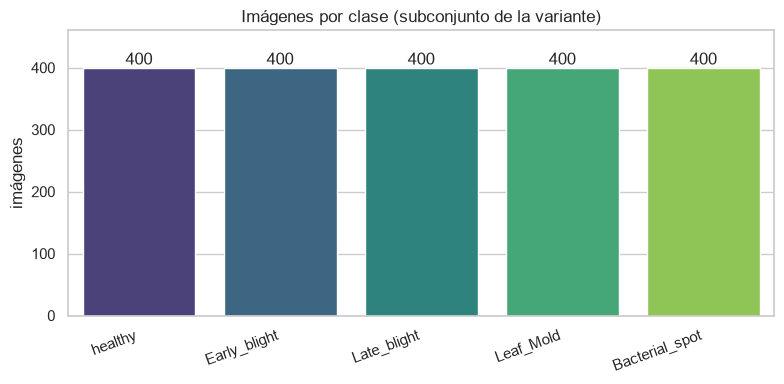

Clases perfectamente balanceadas: True | línea base al azar: 20%


In [9]:
conteo = todos["label"].value_counts().reindex(SELECTED_CLASSES)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=CORTO, y=conteo.values, ax=ax, palette="viridis")
for i, v in enumerate(conteo.values):
    ax.text(i, v + 5, str(v), ha="center")
ax.set_title("Imágenes por clase (subconjunto de la variante)")
ax.set_ylabel("imágenes")
ax.set_ylim(0, conteo.max() * 1.15)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
save_fig("cnn_02_distribucion_clases.png")
plt.show()

balanceado = conteo.nunique() == 1
print("Clases perfectamente balanceadas:", balanceado,
      "| línea base al azar:", f"{1 / NUM_CLASSES:.0%}")

**Lectura:** el tope de 400 imágenes por clase deja las cinco clases con el mismo tamaño. Consecuencias: el accuracy es interpretable (no se infla prediciendo la clase mayoritaria porque no la hay) y la línea base al azar es 20 %. No hace falta ponderar clases.

### 2.3 Control de calidad

In [10]:
registros = []
for fila in todos.itertuples():
    try:
        with Image.open(fila.path) as img:
            registros.append({"label": fila.label, "ancho": img.width, "alto": img.height,
                              "modo": img.mode, "corrupta": False})
    except Exception:
        registros.append({"label": fila.label, "ancho": np.nan, "alto": np.nan,
                          "modo": None, "corrupta": True})

calidad = pd.DataFrame(registros)
N_CORRUPTAS = int(calidad["corrupta"].sum())
MODOS = calidad["modo"].value_counts().to_dict()
RESOLUCIONES = {f"{int(a)}x{int(b)}": int(n)
                for (a, b), n in calidad.dropna(subset=["ancho"]).groupby(["ancho", "alto"]).size().items()}
DUPLICADOS = int(todos["path"].duplicated().sum())

print("Imágenes corruptas      :", N_CORRUPTAS)
print("Modos de color          :", MODOS)
print("Resoluciones            :", RESOLUCIONES)
print("Rutas duplicadas        :", DUPLICADOS)

Imágenes corruptas      : 0
Modos de color          : {'RGB': 2000}
Resoluciones            : {'256x256': 2000}
Rutas duplicadas        : 0


### 2.4 Exploración visual

Figura guardada: cnn_02_ejemplos_por_clase.png


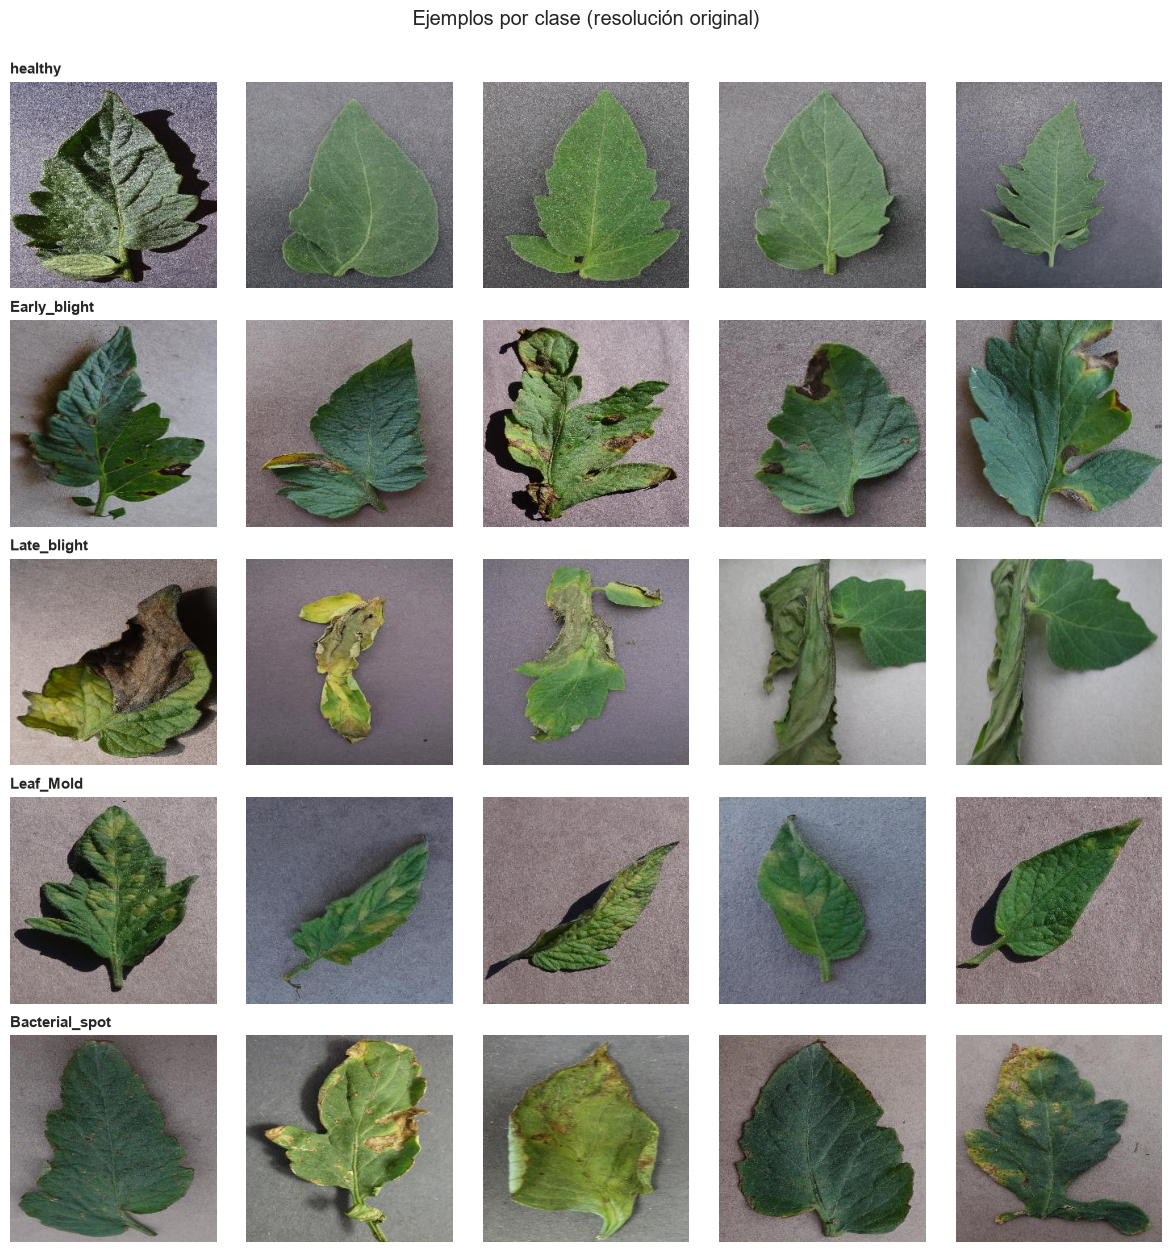

In [11]:
rng = np.random.RandomState(SEED)
fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(12, 2.5 * NUM_CLASSES))
for i, clase in enumerate(SELECTED_CLASSES):
    rutas = todos.loc[todos["label"] == clase, "path"].to_numpy()
    for j, ruta in enumerate(rng.choice(rutas, 5, replace=False)):
        with Image.open(ruta) as img:
            axes[i, j].imshow(img)
        axes[i, j].axis("off")
    axes[i, 0].set_title(CORTO[i], loc="left", fontsize=11, fontweight="bold")
plt.suptitle("Ejemplos por clase (resolución original)", y=1.0)
plt.tight_layout()
save_fig("cnn_02_ejemplos_por_clase.png")
plt.show()

### 2.5 Color promedio por clase

En la EP1 esto anticipó qué clases podría separar un MLP (que solo aprovecha diferencias globales de color). Se repite para contrastar luego con lo que logra una CNN, que sí puede usar **forma y textura de la lesión**.

Figura guardada: cnn_02_color_por_clase.png


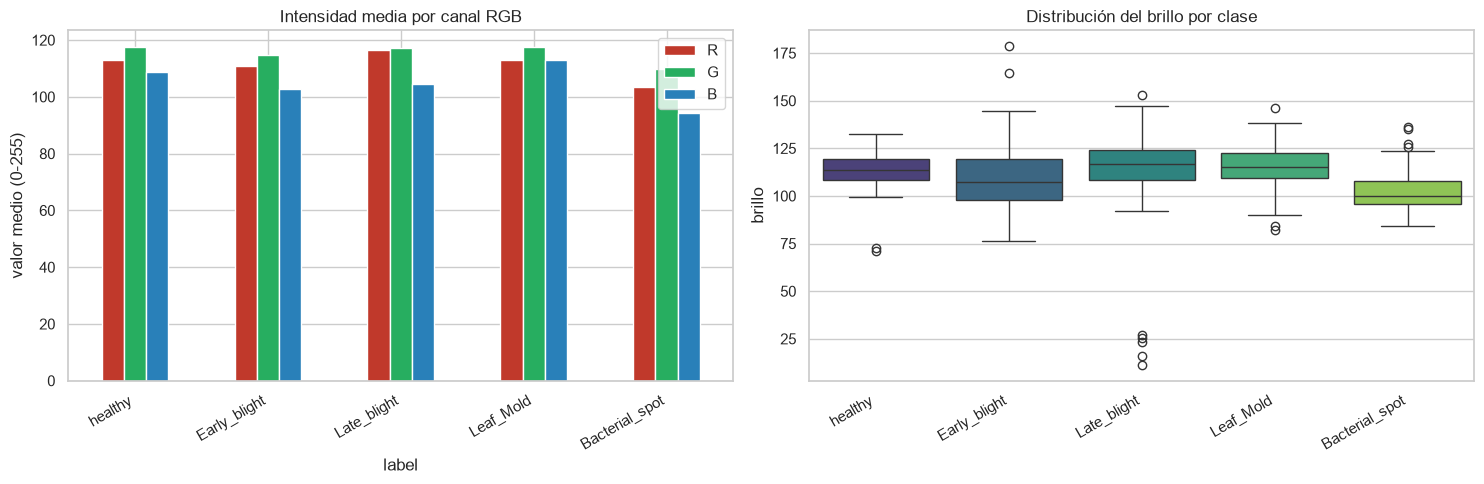

,R,G,B,brillo
label,,,,
Tomato_healthy,112.900002,117.500000,108.599998,113.000000
Tomato_Early_blight,110.900002,114.599998,102.699997,109.400002
Tomato_Late_blight,116.400002,117.300003,104.500000,112.699997
Tomato_Leaf_Mold,113.099998,117.500000,112.900002,114.500000
Tomato_Bacterial_spot,103.300003,109.800003,94.199997,102.400002


In [12]:
def color_promedio(ruta, tamano=IMG_SIZE):
    with Image.open(ruta) as img:
        arr = np.asarray(img.convert("RGB").resize(tamano), dtype=np.float32)
    return arr.reshape(-1, 3).mean(axis=0)


muestra = todos.groupby("label", group_keys=False).head(80)
canales = np.stack([color_promedio(p) for p in muestra["path"]])
color_df = pd.DataFrame(canales, columns=["R", "G", "B"])
color_df["label"] = muestra["label"].values
color_df["brillo"] = color_df[["R", "G", "B"]].mean(axis=1)

resumen_color = color_df.groupby("label")[["R", "G", "B", "brillo"]].mean().reindex(SELECTED_CLASSES).round(1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
resumen_color[["R", "G", "B"]].plot(kind="bar", ax=axes[0], color=["#c0392b", "#27ae60", "#2980b9"])
axes[0].set_title("Intensidad media por canal RGB")
axes[0].set_ylabel("valor medio (0-255)")
axes[0].set_xticklabels(CORTO, rotation=30, ha="right")
sns.boxplot(data=color_df, x="label", y="brillo", order=SELECTED_CLASSES, ax=axes[1], palette="viridis")
axes[1].set_title("Distribución del brillo por clase")
axes[1].set_xticklabels(CORTO, rotation=30, ha="right")
axes[1].set_xlabel("")
plt.tight_layout()
save_fig("cnn_02_color_por_clase.png")
plt.show()
resumen_color

**Lectura:** el color global separa algunas clases (`Bacterial_spot` es más oscura, `Leaf_Mold` destaca en azul) pero `Early_blight` y `Late_blight` tienen perfiles de color muy parecidos: lo que las distingue es la **forma** de la lesión (anillos concéntricos vs. mancha irregular con halo). Ese es justamente el tipo de patrón que una convolución puede capturar y un MLP sobre píxeles planos no.

---

## 3. Preparación de los datos para la CNN

Diferencias respecto del MLP (EP1):

| Paso | MLP (EP1) | CNN (EP2) |
|---|---|---|
| Redimensionado | 64×64 | **64×64** (igual → comparación justa) |
| Normalización | ÷255 → [0,1] | **÷255 → [0,1]** (igual) |
| Forma del dato | `Flatten()` → vector de 12.288 | **Se conserva el tensor 64×64×3** (alto × ancho × canales) |
| Partición | 70/15/15 estratificada | **La misma** (leída de la EP1) |
| Aumento de datos | espejo horizontal + rotación | **El mismo**, dentro del modelo (solo actúa al entrenar) |

La única decisión que cambia es **no aplanar**: la CNN necesita saber qué píxeles son vecinos.

### 3.1 Carga, redimensionado y normalización

In [13]:
INPUT_SHAPE = (*IMG_SIZE, N_CHANNELS)


def cargar_conjunto(dataframe, nombre):
    """Carga un subconjunto a memoria como tensor (N, alto, ancho, canales) en [0, 1].

    Idéntico al preprocesamiento de la EP1 (mismo remuestreo BILINEAR y mismo
    escalado), pero SIN aplanar: se conserva el formato matricial de la imagen.
    """
    X = np.zeros((len(dataframe), *INPUT_SHAPE), dtype=np.float32)
    for i, ruta in enumerate(dataframe["path"]):
        with Image.open(ruta) as img:
            arr = np.asarray(img.convert("RGB").resize(IMG_SIZE, Image.BILINEAR), dtype=np.float32)
        X[i] = arr / 255.0
    y = dataframe["label_id"].to_numpy(dtype=np.int32)
    print(f"{nombre:<14} X={X.shape}  y={y.shape}  dtype={X.dtype}")
    return X, y


X_train, y_train = cargar_conjunto(train_df, "entrenamiento")
X_val, y_val = cargar_conjunto(val_df, "validación")
X_test, y_test = cargar_conjunto(test_df, "prueba")

entrenamiento  X=(1400, 64, 64, 3)  y=(1400,)  dtype=float32
validación     X=(300, 64, 64, 3)  y=(300,)  dtype=float32


prueba         X=(300, 64, 64, 3)  y=(300,)  dtype=float32


Rango en entrenamiento: [0.000, 0.996]
Media: 0.430   Desviación estándar: 0.170
Normalización consistente en train/val/test ✓


Figura guardada: cnn_03_preprocesamiento.png


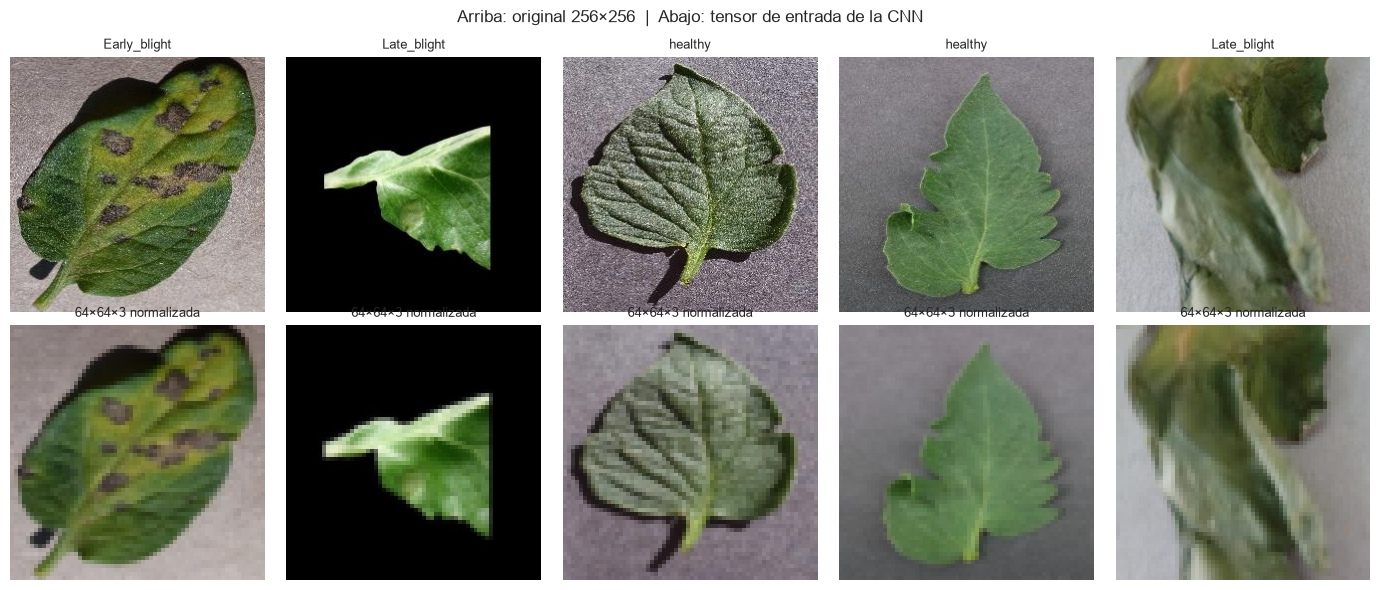

In [14]:
# Verificación del preprocesamiento
print(f"Rango en entrenamiento: [{X_train.min():.3f}, {X_train.max():.3f}]")
print(f"Media: {X_train.mean():.3f}   Desviación estándar: {X_train.std():.3f}")
assert 0.0 <= X_train.min() and X_train.max() <= 1.0, "Los píxeles no están normalizados en [0, 1]"
assert not np.isnan(X_train).any(), "Hay NaN en las imágenes"
for nombre, X in (("val", X_val), ("test", X_test)):
    assert 0.0 <= X.min() and X.max() <= 1.0, f"{nombre} no está normalizado"
print("Normalización consistente en train/val/test ✓")

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for j in range(5):
    with Image.open(train_df.loc[j, "path"]) as img:
        axes[0, j].imshow(img)
    axes[0, j].set_title(train_df.loc[j, "label"].replace("Tomato_", ""), fontsize=9)
    axes[0, j].axis("off")
    axes[1, j].imshow(X_train[j])
    axes[1, j].set_title("64×64×3 normalizada", fontsize=9)
    axes[1, j].axis("off")
plt.suptitle("Arriba: original 256×256  |  Abajo: tensor de entrada de la CNN", fontsize=12)
plt.tight_layout()
save_fig("cnn_03_preprocesamiento.png")
plt.show()

### 3.2 Aumento de datos

Con solo 1.400 imágenes de entrenamiento, exponer la red a pequeñas variaciones (espejo horizontal, rotación leve) reduce la memorización de la posición exacta de cada lesión. Son capas de Keras que **solo actúan al entrenar** (`training=True`); al evaluar son transparentes. Se usa exactamente la misma configuración del MLP.

Figura guardada: cnn_03_aumento_datos.png


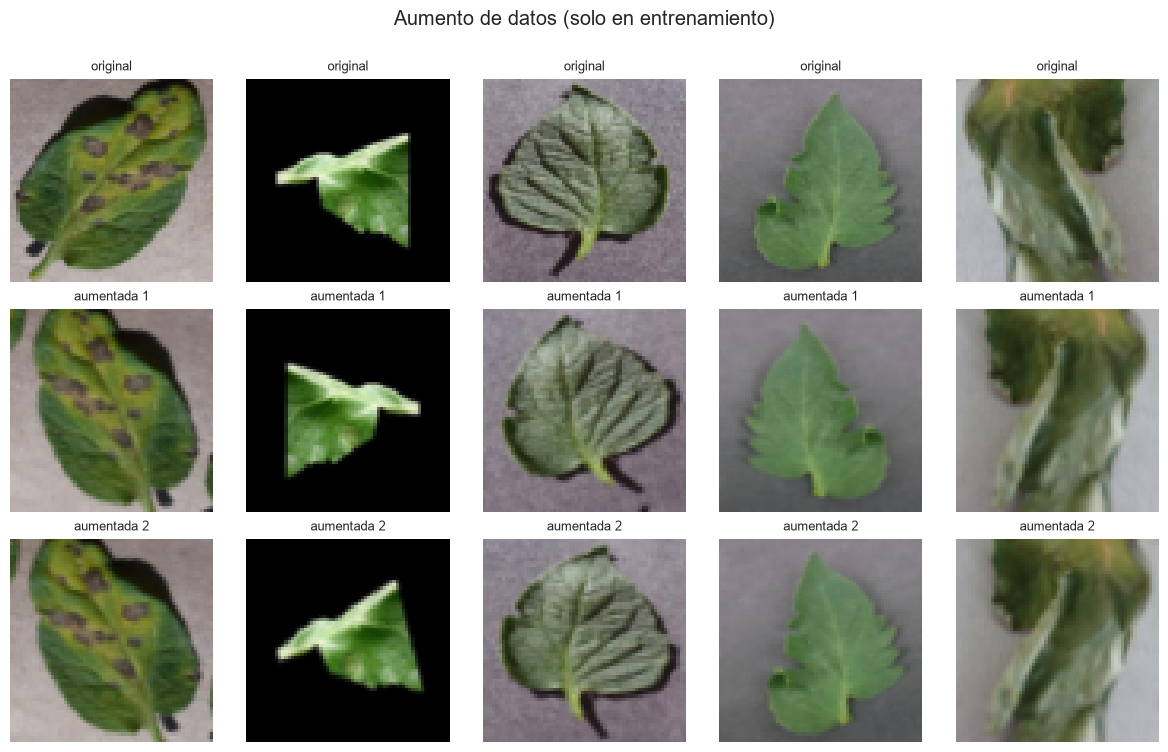

In [15]:
flip = layers.RandomFlip("horizontal")
rot = layers.RandomRotation(0.05)          # ±0,05 vueltas ≈ ±18°

fig, axes = plt.subplots(3, 5, figsize=(12, 7.5))
for j in range(5):
    base = X_train[j:j + 1]
    axes[0, j].imshow(base[0])
    axes[0, j].set_title("original", fontsize=9)
    for k in (1, 2):
        aug = rot(flip(base, training=True), training=True)
        axes[k, j].imshow(np.clip(aug.numpy()[0], 0, 1))
        axes[k, j].set_title(f"aumentada {k}", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Aumento de datos (solo en entrenamiento)", y=1.0)
plt.tight_layout()
save_fig("cnn_03_aumento_datos.png")
plt.show()

---

## 4. Diseño de la Red Neuronal Convolucional

### 4.1 Arquitectura y justificación

```
Entrada 64×64×3
  └─ [Aumento de datos: espejo horizontal + rotación ±18°]      (solo en entrenamiento)
  └─ Bloque 1: Conv2D(32, 3×3, same) → BatchNorm → ReLU → MaxPool(2×2)   → 32×32×32
  └─ Bloque 2: Conv2D(64, 3×3, same) → BatchNorm → ReLU → MaxPool(2×2)   → 16×16×64
  └─ Bloque 3: Conv2D(128, 3×3, same) → BatchNorm → ReLU → MaxPool(2×2)  →  8×8×128
  └─ Flatten                                                              → 8.192
  └─ Dense(128, ReLU) → Dropout(0,4)
  └─ Dense(5) → Softmax
```

| Decisión | Valor | Justificación técnica |
|---|---|---|
| **Capas convolucionales** | 3 bloques | Cada bloque apila un nivel de la jerarquía visual (bordes → texturas → partes de la lesión). Con 64×64 px, tres reducciones a la mitad dejan mapas de 8×8 sin colapsar la imagen. Grad-CAM se calcula sobre `relu3` (16×16, antes del último pooling) para conservar más resolución espacial. Más bloques se prueban en 5.4. |
| **Tamaño de filtro** | 3×3 | Kernel pequeño y apilable: tres 3×3 consecutivos cubren un campo receptivo mayor con menos parámetros que un solo kernel grande. Es la elección estándar (VGG). |
| **Número de filtros** | 32 → 64 → 128 | Se duplica al bajar la resolución: las primeras capas necesitan pocos patrones simples; las profundas combinan muchos patrones. Compensa la pérdida espacial del pooling. |
| **Padding** | `same` | Conserva el tamaño tras cada convolución; la reducción la hace solo el pooling. Evita perder información de los bordes (las lesiones pueden estar en el borde de la hoja). |
| **Activación** | ReLU | La convolución es lineal; ReLU aporta la no linealidad, es barata y mitiga el desvanecimiento del gradiente. |
| **BatchNormalization** | tras cada Conv | Estabiliza el entrenamiento y permite usar `lr = 0,001`. Mismo criterio que en el MLP. |
| **Pooling** | MaxPool 2×2 | Reduce a la mitad el alto y ancho, aporta tolerancia a pequeños desplazamientos y conserva la activación más fuerte (la *presencia* del patrón, no su posición exacta). El pooling no extrae características: solo condensa. |
| **Capas densas** | Dense(128) + Dropout(0,4) | Tras `Flatten` (8.192 valores ya *extraídos* por las convoluciones) se combinan en un clasificador denso. Esta capa concentra la mayoría de los parámetros, por eso el Dropout es algo mayor que el 0,3 del MLP. |
| **Salida** | Dense(5) + Softmax | Cinco clases excluyentes → distribución de probabilidad. La capa lineal (*logits*) se deja con nombre propio porque Grad-CAM deriva sobre ella (evita gradientes nulos cuando el softmax satura). |
| **Función de pérdida** | `sparse_categorical_crossentropy` | Etiquetas enteras 0–4; la estándar para multiclase. Igual que el MLP. |
| **Optimizador** | Adam, `lr = 0,001` + `ReduceLROnPlateau` | El barrido de la EP1 mostró `lr = 0,001` como el punto estable; se mantiene el mismo protocolo para comparar. |
| **Hiperparámetros de entrenamiento** | `batch = 32`, hasta 60 épocas, `EarlyStopping(patience=8)` con restauración de la mejor época | Idénticos al MLP: así la única diferencia entre modelos es la arquitectura. |

### 4.2 Implementación

In [16]:
def nombre_valido(texto):
    """Keras solo acepta letras, dígitos, '.', '_', '/' y '-' en el nombre."""
    limpio = re.sub(r"[^A-Za-z0-9_.\-]", "_", texto).strip("_")
    return limpio or "modelo"


def construir_cnn(
    filtros=(32, 64, 128),
    dropout=0.40,
    dense_units=128,
    learning_rate=0.001,
    usar_augmentation=True,
    usar_batchnorm=True,
    nombre="CNN",
):
    """Construye y compila la CNN. Parametrizada para poder comparar variantes en 5.4."""
    capas = [layers.Input(shape=INPUT_SHAPE, name="entrada")]

    if usar_augmentation:   # solo activas con training=True
        capas.append(layers.RandomFlip("horizontal", name="aug_espejo"))
        capas.append(layers.RandomRotation(0.05, name="aug_rotacion"))

    for i, f in enumerate(filtros, start=1):
        capas.append(layers.Conv2D(f, (3, 3), padding="same",
                                   kernel_initializer="he_normal", name=f"conv{i}"))
        if usar_batchnorm:
            capas.append(layers.BatchNormalization(name=f"bn{i}"))
        capas.append(layers.Activation("relu", name=f"relu{i}"))
        capas.append(layers.MaxPooling2D((2, 2), name=f"pool{i}"))

    capas.append(layers.Flatten(name="flatten"))
    capas.append(layers.Dense(dense_units, activation="relu",
                              kernel_initializer="he_normal", name="densa1"))
    if dropout:
        capas.append(layers.Dropout(dropout, name="dropout1"))

    # Logits y softmax separados: Grad-CAM deriva sobre los logits (ver sección 8)
    capas.append(layers.Dense(NUM_CLASSES, name="logits"))
    capas.append(layers.Softmax(name="softmax"))

    modelo = Sequential(capas, name=nombre_valido(nombre))
    modelo.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return modelo


tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

cnn = construir_cnn(nombre="CNN_PlantVillage")
cnn.summary()

Model: "CNN_PlantVillage"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aug_espejo (RandomFlip)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_rotacion (RandomRotation)   │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 64, 64, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 32, 32, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 16, 16, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (Activation)              │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa1 (Dense)                  │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout1 (Dropout)              │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 5)              │           645 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax (Softmax)               │ (None, 5)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,143,493 (4.36 MB)

 Trainable params: 1,143,045 (4.36 MB)

 Non-trainable params: 448 (1.75 KB)

### 4.3 Cuenta de parámetros y campo receptivo

Una capa convolucional tiene `K · (F · F · C_entrada) + K` parámetros (K filtros de F×F×C más un sesgo por filtro). No depende del tamaño de la imagen: es la razón por la que una CNN necesita muchos menos parámetros que un MLP para el mismo problema.

In [17]:
def campo_receptivo(modelo):
    """Campo receptivo (en píxeles de la entrada) de cada capa convolucional."""
    r, j = 1, 1                       # tamaño del campo y salto acumulado
    resultado = {}
    for capa in modelo.layers:
        if isinstance(capa, (layers.Conv2D, layers.MaxPooling2D)):
            k = capa.kernel_size[0] if isinstance(capa, layers.Conv2D) else capa.pool_size[0]
            s = (capa.strides[0] if capa.strides else k)
            r += (k - 1) * j
            j *= s
            if isinstance(capa, layers.Conv2D):
                resultado[capa.name] = r
    return resultado


filas = []
for capa in cnn.layers:
    filas.append({
        "capa": capa.name,
        "tipo": capa.__class__.__name__,
        "salida": str(tuple(capa.output.shape[1:])),
        "parámetros": capa.count_params(),
    })
tabla_capas = pd.DataFrame(filas)

TOTAL_PARAMS_CNN = cnn.count_params()
PARAMS_DENSA1 = cnn.get_layer("densa1").count_params()
CAMPOS = campo_receptivo(cnn)

# Verificación de la fórmula con la primera capa: 32 · (3·3·3) + 32
assert cnn.get_layer("conv1").count_params() == 32 * (3 * 3 * 3) + 32

print(f"Parámetros totales            : {TOTAL_PARAMS_CNN:,}")
print(f"Capa densa (Flatten → 128)    : {PARAMS_DENSA1:,} ({PARAMS_DENSA1 / TOTAL_PARAMS_CNN:.1%} del total)")
print(f"Capas convolucionales (suma)  : {sum(cnn.get_layer(f'conv{i}').count_params() for i in (1, 2, 3)):,}")
print(f"Imágenes de entrenamiento     : {len(X_train):,}")
print(f"Razón parámetros / imágenes   : {TOTAL_PARAMS_CNN / len(X_train):,.0f} a 1")
print("Campo receptivo por capa conv :", {k: f"{v}×{v} px" for k, v in CAMPOS.items()})
tabla_capas

Parámetros totales            : 1,143,493
Capa densa (Flatten → 128)    : 1,048,704 (91.7% del total)
Capas convolucionales (suma)  : 93,248
Imágenes de entrenamiento     : 1,400
Razón parámetros / imágenes   : 817 a 1
Campo receptivo por capa conv : {'conv1': '3×3 px', 'conv2': '8×8 px', 'conv3': '18×18 px'}


,capa,tipo,salida,parámetros
0,aug_espejo,RandomFlip,"(64, 64, 3)",0
1,aug_rotacion,RandomRotation,"(64, 64, 3)",0
2,conv1,Conv2D,"(64, 64, 32)",896
3,bn1,BatchNormalization,"(64, 64, 32)",128
4,relu1,Activation,"(64, 64, 32)",0
5,pool1,MaxPooling2D,"(32, 32, 32)",0
6,conv2,Conv2D,"(32, 32, 64)",18496
7,bn2,BatchNormalization,"(32, 32, 64)",256
8,relu2,Activation,"(32, 32, 64)",0
9,pool2,MaxPooling2D,"(16, 16, 64)",0


**Lectura:** las tres capas convolucionales suman solo **93.248 parámetros** (896 + 18.496 + 73.856), porque cada filtro se **comparte** en toda la imagen. La capa densa posterior al `Flatten` concentra **1.048.704** (91,7 % del total). El modelo completo tiene **1.143.493** parámetros, el **36 % del MLP** de la EP1 (3.181.061): la convolución extrae características locales en vez de conectar cada píxel con cada neurona.

El campo receptivo crece con la profundidad: **3×3 px** en `conv1`, **8×8** en `conv2` y **18×18** en `conv3`. Una neurona de la última capa convolucional "ve" un área 36 veces mayor que una de la primera: así se construye la jerarquía *borde → textura → parte de la lesión*.


In [18]:
def crear_callbacks(verbose=0):
    return [
        EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=verbose),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=verbose),
    ]


t0 = time.perf_counter()
history = cnn.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=crear_callbacks(verbose=1),
    verbose=2,
)
TIEMPO_CNN = time.perf_counter() - t0
EPOCAS_CNN = len(history.history["loss"])

print(f"\nÉpocas ejecutadas: {EPOCAS_CNN} (tope {EPOCHS})")
print(f"Tiempo de entrenamiento: {TIEMPO_CNN:.1f} s  ({TIEMPO_CNN / EPOCAS_CNN:.2f} s por época)")

Epoch 1/60


44/44 - 2s - 43ms/step - accuracy: 0.4157 - loss: 2.1114 - val_accuracy: 0.2400 - val_loss: 1.6053 - learning_rate: 0.0010


Epoch 2/60


44/44 - 1s - 20ms/step - accuracy: 0.5800 - loss: 1.0106 - val_accuracy: 0.2800 - val_loss: 1.5951 - learning_rate: 0.0010


Epoch 3/60


...


Epoch 36: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.


44/44 - 1s - 19ms/step - accuracy: 0.8714 - loss: 0.3006 - val_accuracy: 0.9000 - val_loss: 0.2562 - learning_rate: 1.2500e-04


Epoch 36: early stopping


Restoring model weights from the end of the best epoch: 28.



Épocas ejecutadas: 36 (tope 60)
Tiempo de entrenamiento: 31.6 s  (0.88 s por época)


### 5.3 Curvas de aprendizaje

Las curvas se leen **antes** de mirar la prueba. La señal de sobreajuste es una brecha creciente entre la curva de entrenamiento y la de validación.

Figura guardada: cnn_05_curvas_aprendizaje.png


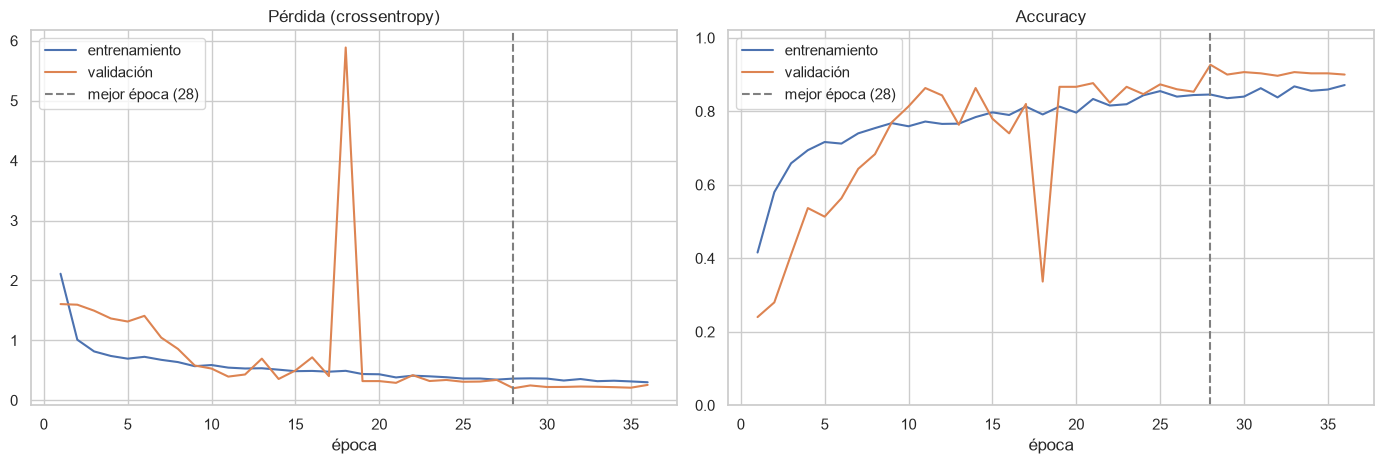

In [19]:
hist = pd.DataFrame(history.history)
mejor_epoca = int(hist["val_loss"].idxmin()) + 1
epocas = np.arange(1, len(hist) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(epocas, hist["loss"], label="entrenamiento")
axes[0].plot(epocas, hist["val_loss"], label="validación")
axes[0].axvline(mejor_epoca, color="gray", ls="--", label=f"mejor época ({mejor_epoca})")
axes[0].set_title("Pérdida (crossentropy)")
axes[0].set_xlabel("época")
axes[0].legend()

axes[1].plot(epocas, hist["accuracy"], label="entrenamiento")
axes[1].plot(epocas, hist["val_accuracy"], label="validación")
axes[1].axvline(mejor_epoca, color="gray", ls="--", label=f"mejor época ({mejor_epoca})")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("época")
axes[1].set_ylim(0, 1.02)
axes[1].legend()
plt.tight_layout()
save_fig("cnn_05_curvas_aprendizaje.png")
plt.show()

In [20]:
# restore_best_weights=True: el modelo en memoria es el de la MEJOR época, así que el
# diagnóstico lee esa fila (mirar la última describiría un modelo ya descartado).
fila_mejor = hist.loc[mejor_epoca - 1]
fila_final = hist.iloc[-1]
brecha_mejor = fila_mejor["accuracy"] - fila_mejor["val_accuracy"]
brecha_final = fila_final["accuracy"] - fila_final["val_accuracy"]
corto_por_early_stopping = len(hist) < EPOCHS

print(f"Épocas ejecutadas: {len(hist)} de un tope de {EPOCHS}")
print("  EarlyStopping detuvo el entrenamiento antes del tope."
      if corto_por_early_stopping else
      "  Se alcanzó el tope de épocas: EarlyStopping NO llegó a activarse.")
print(f"Mejor época (menor val_loss): {mejor_epoca}\n")
print(f"--- Modelo conservado (época {mejor_epoca}) ---")
print(f"  accuracy entrenamiento : {fila_mejor['accuracy']:.4f}")
print(f"  accuracy validación    : {fila_mejor['val_accuracy']:.4f}")
print(f"  val_loss               : {fila_mejor['val_loss']:.4f}")
print(f"  brecha train − val     : {brecha_mejor:.4f}")
print(f"--- Última época ({len(hist)}), descartada ---")
print(f"  brecha train − val     : {brecha_final:.4f}\n")

if brecha_mejor > 0.15:
    DIAGNOSTICO = "sobreajuste incluso en la mejor época"
elif fila_mejor["accuracy"] < 0.50:
    DIAGNOSTICO = "underfitting: capacidad o entrenamiento insuficientes"
else:
    DIAGNOSTICO = "ajuste razonable en el modelo conservado"
print("DIAGNÓSTICO:", DIAGNOSTICO)

if not corto_por_early_stopping:
    print("\nATENCIÓN: no se alcanzó la condición de EarlyStopping. Revisa las curvas: si "
          "val_loss sigue bajando al final, el tope de épocas quedó corto.")

Épocas ejecutadas: 36 de un tope de 60
  EarlyStopping detuvo el entrenamiento antes del tope.
Mejor época (menor val_loss): 28

--- Modelo conservado (época 28) ---
  accuracy entrenamiento : 0.8457
  accuracy validación    : 0.9267
  val_loss               : 0.2010
  brecha train − val     : -0.0810
--- Última época (36), descartada ---
  brecha train − val     : -0.0286

DIAGNÓSTICO: ajuste razonable en el modelo conservado


**Lectura de las curvas.**

- `EarlyStopping` detuvo el entrenamiento en la época 36 y restauró la **28** (menor `val_loss` = 0,201; accuracy de validación 0,927).
- La accuracy de **validación queda por encima de la de entrenamiento** casi todo el tiempo. No es un error: la accuracy de entrenamiento que reporta Keras se mide **con el aumento de datos y el Dropout activos** (la red ve imágenes rotadas y con neuronas apagadas), mientras que en validación ambos se desactivan. Por eso la brecha de generalización se calcula con la accuracy de entrenamiento **en modo inferencia** (sección 6.4): 0,971 frente a 0,910 en prueba.
- En la **época 18** la validación colapsa durante una sola época (`val_loss` 5,89; accuracy 0,34) y se recupera de inmediato. Es una inestabilidad típica de BatchNormalization con lotes pequeños (las estadísticas acumuladas se desajustan un momento). `ReduceLROnPlateau` bajó la tasa a 0,0005 en la época 19, y después a 0,00025 y 0,000125. Desde ahí las curvas se estabilizan.
- **No hay sobreajuste** en el modelo conservado: la pérdida de validación acompaña a la de entrenamiento y no se separa de ella.


### 5.4 Experimentación: justificar las decisiones de diseño

Para respaldar con evidencia las decisiones de la sección 4 se entrena la arquitectura base y cuatro variantes con **el mismo protocolo** (mismos datos, callbacks y semilla). Se reporta la métrica en la **mejor época** (la que `EarlyStopping` conserva) y se mide solo sobre **validación**: la prueba no se toca hasta la sección 6.

| Variante | Qué pregunta responde |
|---|---|
| A · 2 bloques (32, 64) | ¿Hace falta tanta profundidad? |
| B · 3 bloques (32, 64, 128) — **base** | Referencia |
| C · 4 bloques (32, 64, 128, 256) | ¿Más profundidad mejora o sobreajusta? |
| B sin aumento de datos | ¿Cuánto aporta el aumento de datos? |
| B sin dropout | ¿Cuánto aporta el dropout? |

In [21]:
def experimento(nombre, **kwargs):
    """Entrena una configuración y devuelve sus métricas de validación (comparables)."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    m = construir_cnn(nombre=nombre, **kwargs)

    t = time.perf_counter()
    h = m.fit(X_train, y_train, validation_data=(X_val, y_val),
              epochs=EPOCHS_EXP, batch_size=BATCH_SIZE,
              callbacks=crear_callbacks(), verbose=0)
    dt = time.perf_counter() - t

    hh = pd.DataFrame(h.history)
    i = int(hh["val_loss"].idxmin())
    return {
        "configuración": nombre,
        "parámetros": m.count_params(),
        "épocas": len(hh),
        "mejor_época": i + 1,
        "acc_train": round(hh.loc[i, "accuracy"], 4),
        "acc_val": round(hh.loc[i, "val_accuracy"], 4),
        "brecha": round(hh.loc[i, "accuracy"] - hh.loc[i, "val_accuracy"], 4),
        "tiempo_s": round(dt, 1),
    }


comparacion_cnn = None

if RUN_EXPERIMENTS:
    configuraciones = {
        "A · 2 bloques (32,64)": dict(filtros=(32, 64)),
        "B · 3 bloques (32,64,128) [base]": dict(filtros=(32, 64, 128)),
        "C · 4 bloques (32,64,128,256)": dict(filtros=(32, 64, 128, 256)),
        "B sin aumento de datos": dict(usar_augmentation=False),
        "B sin dropout": dict(dropout=0.0),
    }
    resultados = []
    for nombre, cfg in configuraciones.items():
        print("Entrenando:", nombre, flush=True)
        resultados.append(experimento(nombre, **cfg))
    comparacion_cnn = pd.DataFrame(resultados)
else:
    print("RUN_EXPERIMENTS = False: se omite el barrido.")

comparacion_cnn

Entrenando: A · 2 bloques (32,64)


Entrenando: B · 3 bloques (32,64,128) [base]


Entrenando: C · 4 bloques (32,64,128,256)


Entrenando: B sin aumento de datos


Entrenando: B sin dropout


,configuración,parámetros,épocas,mejor_época,acc_train,acc_val,brecha,tiempo_s
0,"A · 2 bloques (32,64)",2117701,36,28,0.8614,0.9133,-0.0519,29.7
1,"B · 3 bloques (32,64,128) [base]",1143493,36,28,0.8457,0.9267,-0.0810,31.4
2,"C · 4 bloques (32,64,128,256)",915397,40,40,0.9664,0.9133,0.0531,40.6
3,B sin aumento de datos,1143493,33,25,0.9493,0.9167,0.0326,27.1
4,B sin dropout,1143493,24,16,0.9736,0.9000,0.0736,22.1


Figura guardada: cnn_05_comparacion_configuraciones.png


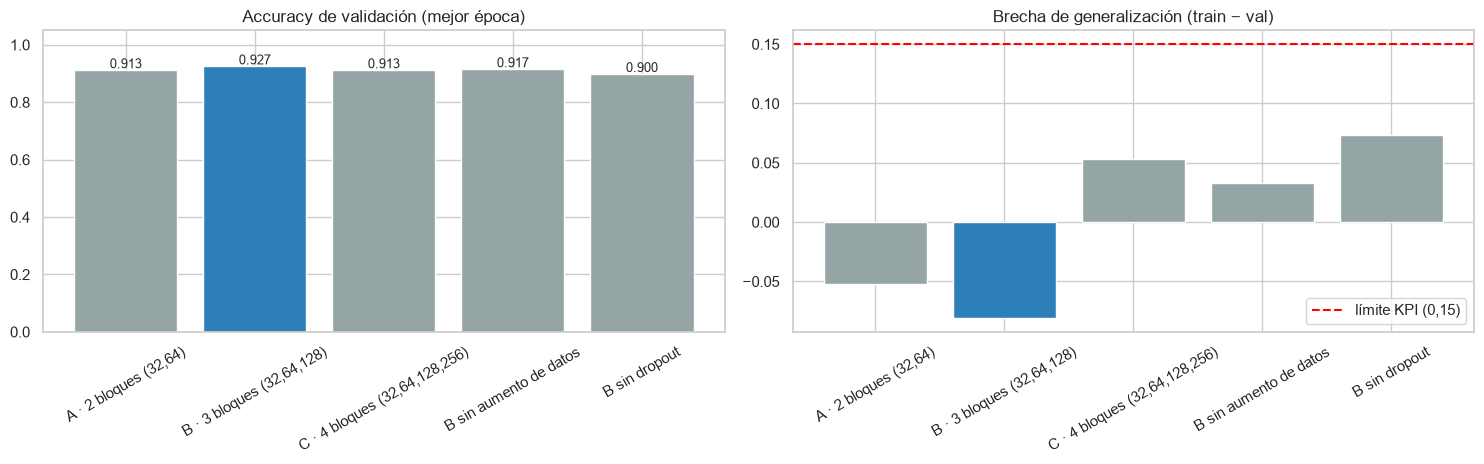

Base: acc_val = 0.9267, brecha = -0.0810
Mejor configuración en validación: B · 3 bloques (32,64,128) [base] (acc_val = 0.9267)
  A · 2 bloques (32,64)              Δ acc_val = -0.0134   brecha = -0.0519
  C · 4 bloques (32,64,128,256)      Δ acc_val = -0.0134   brecha = 0.0531
  B sin aumento de datos             Δ acc_val = -0.0100   brecha = 0.0326
  B sin dropout                      Δ acc_val = -0.0267   brecha = 0.0736

Decisión: ninguna variante supera a la base por más de 3% en validación → se mantiene la arquitectura base.


In [22]:
if comparacion_cnn is not None:
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
    etiquetas = [c.split(" [")[0] for c in comparacion_cnn["configuración"]]
    colores = ["#2c7fb8" if "[base]" in c else "#95a5a6" for c in comparacion_cnn["configuración"]]

    axes[0].bar(etiquetas, comparacion_cnn["acc_val"], color=colores)
    for i, v in enumerate(comparacion_cnn["acc_val"]):
        axes[0].text(i, v + 0.005, f"{v:.3f}", ha="center", fontsize=9)
    axes[0].set_title("Accuracy de validación (mejor época)")
    axes[0].set_ylim(0, 1.05)
    axes[0].tick_params(axis="x", rotation=30)

    axes[1].bar(etiquetas, comparacion_cnn["brecha"], color=colores)
    axes[1].axhline(0.15, color="red", ls="--", label="límite KPI (0,15)")
    axes[1].set_title("Brecha de generalización (train − val)")
    axes[1].legend()
    axes[1].tick_params(axis="x", rotation=30)
    plt.tight_layout()
    save_fig("cnn_05_comparacion_configuraciones.png")
    plt.show()

    # Lectura automática: qué eje movió más la validación
    base = comparacion_cnn[comparacion_cnn["configuración"].str.contains(r"\[base\]")].iloc[0]
    mejor = comparacion_cnn.loc[comparacion_cnn["acc_val"].idxmax()]
    print(f"Base: acc_val = {base['acc_val']:.4f}, brecha = {base['brecha']:.4f}")
    print(f"Mejor configuración en validación: {mejor['configuración']} (acc_val = {mejor['acc_val']:.4f})")
    for _, f in comparacion_cnn.iterrows():
        if "[base]" in f["configuración"]:
            continue
        d = f["acc_val"] - base["acc_val"]
        print(f"  {f['configuración']:<34} Δ acc_val = {d:+.4f}   brecha = {f['brecha']:.4f}")

    # Criterio de decisión fijado ANTES de mirar los resultados: con 300 imágenes de
    # validación, 1 imagen = 0,33 pp. Solo se cambia la base si otra variante la supera
    # por más de 3 pp (≈ 9 imágenes) sin aumentar la brecha por encima del KPI.
    UMBRAL_PP = 0.03
    supera = comparacion_cnn[(comparacion_cnn["acc_val"] - base["acc_val"] > UMBRAL_PP)
                             & (comparacion_cnn["brecha"] <= 0.15)]
    if supera.empty:
        print(f"\nDecisión: ninguna variante supera a la base por más de {UMBRAL_PP:.0%} "
              "en validación → se mantiene la arquitectura base.")
    else:
        print("\nDecisión: hay variantes que superan claramente a la base en validación:",
              ", ".join(supera["configuración"]), "→ se discute en el informe.")

**Lectura del barrido** (accuracy de validación en la mejor época; la "brecha" aquí es entrenamiento con aumento/dropout − validación):

| Variante | Parámetros | acc. val. | Brecha | Lectura |
|---|---|---|---|---|
| A · 2 bloques | 2,12 M | 0,913 | −0,05 | Con un bloque menos el `Flatten` recibe 16×16×64 = 16.384 valores: casi el doble de parámetros y no mejora. |
| **B · 3 bloques (base)** | **1,14 M** | **0,927** | **−0,08** | Mejor resultado y menor brecha. |
| C · 4 bloques | 0,92 M | 0,913 | +0,05 | Menos parámetros, pero llega al tope de 40 épocas sin converger y la brecha aumenta. |
| B sin aumento de datos | 1,14 M | 0,917 | +0,03 | La brecha pasa de −0,08 a +0,03: el aumento de datos está regularizando. |
| B sin dropout | 1,14 M | 0,900 | +0,07 | La peor variante: sin Dropout la capa densa memoriza (mayor brecha). |

**Cómo leerla.** Con 300 imágenes de validación, 1 punto porcentual equivale a 3 imágenes. Las diferencias observadas (≤ 2,7 pp, ≤ 8 imágenes) **no son concluyentes por sí solas**. Lo que sí es consistente es la dirección: **quitar regularización (aumento o Dropout) siempre aumenta la brecha**, y ni más ni menos profundidad mejora a la base. Según el criterio fijado de antemano (cambiar la base solo si otra variante la supera por más de 3 pp), **se mantiene la arquitectura base**. El conjunto de prueba **no se usó** para elegir, de modo que el resultado de la sección 6 sigue siendo una estimación honesta.


In [23]:
# Resultados del MLP (EP1), leídos de sus artefactos
mlp_global = pd.read_csv(EP1_DIR / "metricas_globales.csv", index_col=0)["valor"]
mlp_por_clase = pd.read_csv(EP1_DIR / "metricas_por_clase.csv", index_col=0)
mlp_cm_df = pd.read_csv(EP1_DIR / "matriz_confusion.csv", index_col=0)
mlp_hist = pd.read_csv(EP1_DIR / "historial_entrenamiento.csv")
mlp_kpis = pd.read_csv(EP1_DIR / "kpis.csv")

assert list(mlp_cm_df.index) == CORTO, "El orden de clases de la matriz del MLP no coincide"
cm_mlp = mlp_cm_df.to_numpy()

MLP_ACC = float(mlp_global["Accuracy"])
MLP_PREC = float(mlp_global["Precision (macro)"])
MLP_REC = float(mlp_global["Recall (macro)"])
MLP_F1 = float(mlp_global["F1-score (macro)"])
MLP_REC_ENF = float((cm_mlp.diagonal() / cm_mlp.sum(axis=1))[IDX_ENFERMAS].mean())
MLP_FN_CRIT = int(cm_mlp[IDX_ENFERMAS, ID_SANA].sum())          # enfermas → sana
MLP_N_ENFERMAS = int(cm_mlp[IDX_ENFERMAS].sum())
MLP_BRECHA = float(mlp_kpis.loc[mlp_kpis["KPI"] == "Brecha de generalización", "obtenido"].iloc[0])
MLP_EPOCAS = len(mlp_hist)
MLP_MEJOR_EPOCA = int(mlp_hist["val_loss"].idxmin()) + 1

print("MLP (EP1) en prueba:")
print(f"  accuracy {MLP_ACC:.4f} | F1 macro {MLP_F1:.4f} | recall enfermas {MLP_REC_ENF:.4f} "
      f"| enfermas→sana {MLP_FN_CRIT}/{MLP_N_ENFERMAS} | brecha {MLP_BRECHA:.4f}")

MLP (EP1) en prueba:
  accuracy 0.8233 | F1 macro 0.8192 | recall enfermas 0.7792 | enfermas→sana 6/240 | brecha 0.1481


### 6.1 Métricas globales de la CNN

In [24]:
y_prob = cnn.predict(X_test, verbose=0)
y_pred = y_prob.argmax(axis=1)
test_loss, test_accuracy = cnn.evaluate(X_test, y_test, verbose=0)

metricas = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "F1-score (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
    "Precision (weighted)": precision_score(y_test, y_pred, average="weighted", zero_division=0),
    "Recall (weighted)": recall_score(y_test, y_pred, average="weighted", zero_division=0),
    "F1-score (weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0),
}
CNN_ACC = metricas["Accuracy"]
CNN_PREC = metricas["Precision (macro)"]
CNN_REC = metricas["Recall (macro)"]
CNN_F1 = metricas["F1-score (macro)"]

print(f"Pérdida en prueba (crossentropy): {test_loss:.4f}\n")
tabla_metricas = pd.Series(metricas, name="valor").round(4).to_frame()
tabla_metricas

Pérdida en prueba (crossentropy): 0.2403



,valor
Accuracy,0.9100
Precision (macro),0.9172
Recall (macro),0.9100
F1-score (macro),0.9105
Precision (weighted),0.9172
Recall (weighted),0.9100
F1-score (weighted),0.9105


**Qué aporta cada métrica en este problema**

- **Accuracy:** proporción de hojas bien clasificadas. Es interpretable porque las clases están balanceadas.
- **Precision:** de las hojas que el modelo llama "X", cuántas lo son. Una precision baja en una enfermedad implica falsas alarmas (tratamientos innecesarios).
- **Recall:** de las hojas realmente "X", cuántas detecta. En las enfermas, un recall bajo implica plantas sin tratar: es la métrica de mayor costo.
- **F1:** media armónica de precision y recall; penaliza que una de las dos sea mala.
- **Matriz de confusión:** muestra *hacia dónde* se equivoca, que ninguna métrica agregada revela.

### 6.2 Métricas por clase

Figura guardada: cnn_06_metricas_por_clase.png


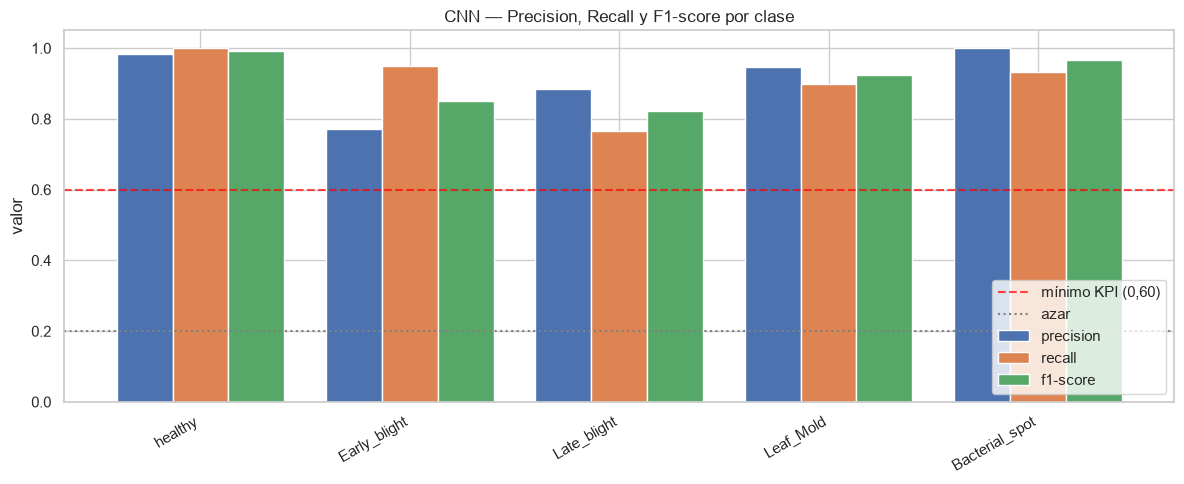

,precision,recall,f1-score,support
healthy,0.9836,1.0000,0.9917,60
Early_blight,0.7703,0.9500,0.8507,60
Late_blight,0.8846,0.7667,0.8214,60
Leaf_Mold,0.9474,0.9000,0.9231,60
Bacterial_spot,1.0000,0.9333,0.9655,60


In [25]:
reporte = classification_report(y_test, y_pred, target_names=CORTO, output_dict=True, zero_division=0)
reporte_df = pd.DataFrame(reporte).transpose().loc[CORTO].round(4)
reporte_df["support"] = reporte_df["support"].astype(int)

reporte_df[["precision", "recall", "f1-score"]].plot(kind="bar", figsize=(12, 5), width=0.8)
plt.axhline(0.60, color="red", linestyle="--", alpha=0.7, label="mínimo KPI (0,60)")
plt.axhline(1 / NUM_CLASSES, color="gray", linestyle=":", label="azar")
plt.title("CNN — Precision, Recall y F1-score por clase")
plt.ylabel("valor")
plt.xlabel("")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.tight_layout()
save_fig("cnn_06_metricas_por_clase.png")
plt.show()
reporte_df

### 6.3 Matriz de confusión

Figura guardada: cnn_06_matriz_confusion.png


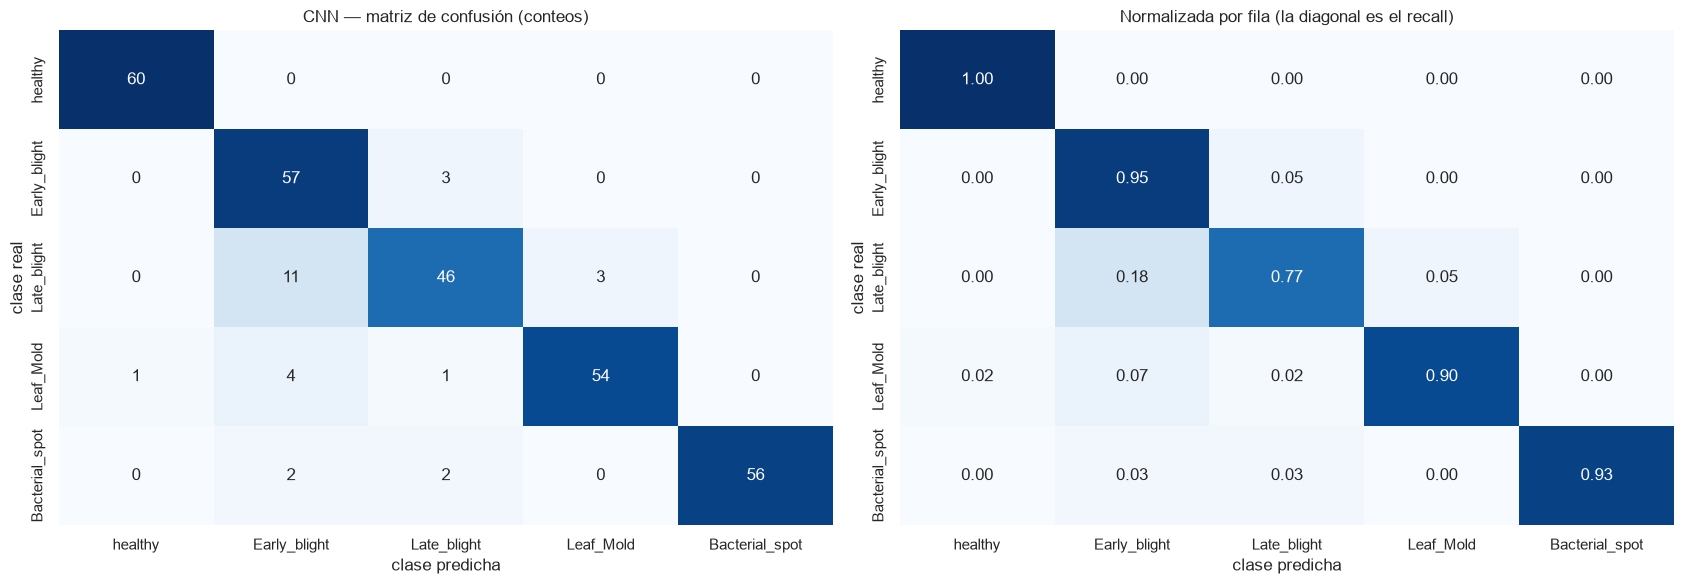

Mejor clasificada : healthy (recall 1.00)
Peor clasificada  : Late_blight (recall 0.77)
Confusión más frecuente: Late_blight → Early_blight (11 hojas)


In [26]:
cm = confusion_matrix(y_test, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=CORTO, yticklabels=CORTO, ax=axes[0])
axes[0].set_title("CNN — matriz de confusión (conteos)")
axes[0].set_xlabel("clase predicha")
axes[0].set_ylabel("clase real")

cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", cbar=False, vmin=0, vmax=1,
            xticklabels=CORTO, yticklabels=CORTO, ax=axes[1])
axes[1].set_title("Normalizada por fila (la diagonal es el recall)")
axes[1].set_xlabel("clase predicha")
axes[1].set_ylabel("clase real")
plt.tight_layout()
save_fig("cnn_06_matriz_confusion.png")
plt.show()

# Lectura automática
recall_por_clase = cm.diagonal() / cm.sum(axis=1)
mejor_c, peor_c = int(recall_por_clase.argmax()), int(recall_por_clase.argmin())
off = cm.copy()
np.fill_diagonal(off, 0)
r_, c_ = np.unravel_index(off.argmax(), off.shape)
HAY_CONFUSIONES = bool(off.max() > 0)
print(f"Mejor clasificada : {CORTO[mejor_c]} (recall {recall_por_clase[mejor_c]:.2f})")
print(f"Peor clasificada  : {CORTO[peor_c]} (recall {recall_por_clase[peor_c]:.2f})")
if HAY_CONFUSIONES:
    print(f"Confusión más frecuente: {CORTO[r_]} → {CORTO[c_]} ({off[r_, c_]} hojas)")
else:
    print("No hubo confusiones entre clases en la prueba.")

**Lectura de las métricas y de la matriz de confusión.**

- **Accuracy 0,910 y F1 macro 0,911** (4,6 veces el azar). Precision y recall macro son casi iguales: no hay un sesgo sistemático a sobre- o sub-predecir.
- **healthy:** recall 1,00 (las 60 sanas reconocidas) y precision 0,98: solo **una** hoja enferma se etiquetó como sana.
- **Bacterial_spot:** precision 1,00. Sus puntos pequeños y oscuros son una textura que los filtros capturan bien.
- **Early_blight:** recall 0,95 pero precision 0,77. Es la clase "imán": de sus 17 falsos positivos, 11 son Late_blight. Cuando la red duda entre los dos tizones, tiende a decir Early_blight.
- **Late_blight:** la clase más difícil (recall 0,77). **11 de sus 14 errores van a Early_blight** y 3 a Leaf_Mold. Ambos tizones son fúngicos y producen lesiones café sobre tejido verde; a 64×64 se pierde parte del detalle que los distingue (anillos concéntricos frente a mancha irregular con halo).
- Esto es coherente con las curvas: el modelo no memorizó y sus errores se concentran en el par visualmente más parecido, no se reparten al azar.


### 6.4 Cumplimiento de los KPIs

In [27]:
def es(x, d=4):
    """Formato con coma decimal (informe en español)."""
    return f"{x:.{d}f}".replace(".", ",")


def pct(x, d=2):
    return f"{100 * x:.{d}f} %".replace(".", ",")


acc_train_eval = accuracy_score(y_train, cnn.predict(X_train, verbose=0).argmax(axis=1))
CNN_ACC_TRAIN = acc_train_eval
CNN_BRECHA = acc_train_eval - test_accuracy
CNN_REC_ENF = float(recall_por_clase[IDX_ENFERMAS].mean())
CNN_FN_CRIT = int(cm[IDX_ENFERMAS, ID_SANA].sum())               # enfermas → sana
N_ENFERMAS_TEST = int(cm[IDX_ENFERMAS].sum())
minimo = min(CNN_ACC, CNN_F1, CNN_REC_ENF)

kpis = pd.DataFrame([
    {"KPI": "Accuracy (test)", "meta": f"> {es(MLP_ACC)} (MLP)",
     "obtenido": es(CNN_ACC), "cumple": CNN_ACC > MLP_ACC},
    {"KPI": "F1-score macro", "meta": f"> {es(MLP_F1)} (MLP)",
     "obtenido": es(CNN_F1), "cumple": CNN_F1 > MLP_F1},
    {"KPI": "Recall clases enfermas", "meta": f"≥ {es(MLP_REC_ENF)} (MLP)",
     "obtenido": es(CNN_REC_ENF), "cumple": CNN_REC_ENF >= MLP_REC_ENF},
    {"KPI": "Enfermas clasificadas como sanas", "meta": f"≤ {MLP_FN_CRIT} (MLP)",
     "obtenido": str(CNN_FN_CRIT), "cumple": CNN_FN_CRIT <= MLP_FN_CRIT},
    {"KPI": "Brecha de generalización", "meta": "≤ 0,15",
     "obtenido": es(CNN_BRECHA), "cumple": CNN_BRECHA <= 0.15},
    {"KPI": "Mínimos EP1 (acc, F1, recall enf. ≥ 0,60)", "meta": "≥ 0,60",
     "obtenido": es(minimo), "cumple": minimo >= 0.60},
])
kpis["cumple"] = kpis["cumple"].map({True: "SÍ", False: "NO"})

print(f"Accuracy entrenamiento (inferencia): {acc_train_eval:.4f}")
print(f"Accuracy prueba                    : {test_accuracy:.4f}")
print(f"Brecha                             : {CNN_BRECHA:.4f}")
print(f"Línea base (azar)                  : {1 / NUM_CLASSES:.4f}")
print(f"Mejora sobre el azar               : {test_accuracy / (1 / NUM_CLASSES):.2f}×\n")
kpis

Accuracy entrenamiento (inferencia): 0.9714
Accuracy prueba                    : 0.9100
Brecha                             : 0.0614
Línea base (azar)                  : 0.2000
Mejora sobre el azar               : 4.55×



,KPI,meta,obtenido,cumple
0,Accuracy (test),"> 0,8233 (MLP)","0,9100",SÍ
1,F1-score macro,"> 0,8192 (MLP)","0,9105",SÍ
2,Recall clases enfermas,"≥ 0,7792 (MLP)","0,8875",SÍ
3,Enfermas clasificadas como sanas,≤ 6 (MLP),1,SÍ
4,Brecha de generalización,"≤ 0,15","0,0614",SÍ
5,"Mínimos EP1 (acc, F1, recall enf. ≥ 0,60)","≥ 0,60","0,8875",SÍ


**Lectura:** se cumplen los **6 KPIs**. Lo más relevante para el negocio es que las hojas **enfermas clasificadas como sanas bajan de 6 a 1** (de 240) y el recall de enfermas sube de 0,779 a 0,888. La brecha de generalización (0,061) es menos de la mitad que la del MLP (0,148).


---

## 7. Comparación MLP vs CNN

Se compara con **evidencia experimental**: mismas imágenes de prueba, misma partición, mismo protocolo de entrenamiento. Dos precauciones:

- Las cifras del MLP son las **oficiales de la EP1** (leídas de sus archivos). Además se vuelve a cargar el modelo del MLP y se verifica que reproduce su accuracy sobre esta misma prueba.
- Los **tiempos** solo son comparables si se miden en el mismo hardware, así que el MLP se reentrena aquí con su configuración original (solo para medir tiempo).

### 7.1 Modelo y predicciones del MLP

In [28]:
def construir_mlp_ep1(hidden_units=(256, 128), dropout_rate=0.30, learning_rate=0.001, l2=1e-4):
    """Réplica EXACTA de la arquitectura del MLP de la EP1 (Flatten → Dense(256) → Dense(128) → Dense(5))."""
    reg = tf.keras.regularizers.l2(l2)
    capas = [layers.Input(shape=INPUT_SHAPE),
             layers.RandomFlip("horizontal"),
             layers.RandomRotation(0.05),
             layers.Flatten()]
    for u in hidden_units:
        capas += [layers.Dense(u, kernel_initializer="he_normal", kernel_regularizer=reg),
                  layers.BatchNormalization(),
                  layers.Activation("relu"),
                  layers.Dropout(dropout_rate)]
    capas.append(layers.Dense(NUM_CLASSES, activation="softmax"))
    m = Sequential(capas, name="MLP_EP1")
    m.compile(optimizer=Adam(learning_rate=learning_rate),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m


mlp_modelo, MLP_REPRODUCE, MLP_ACC_REEVAL, y_pred_mlp = None, None, None, None

if opcionales_ok["mlp_plantvillage.keras"]:
    try:
        mlp_modelo = keras.models.load_model(EP1_DIR / "mlp_plantvillage.keras")
        p_mlp = mlp_modelo.predict(X_test, verbose=0)
        MLP_ACC_REEVAL = accuracy_score(y_test, p_mlp.argmax(axis=1))
        MLP_REPRODUCE = abs(MLP_ACC_REEVAL - MLP_ACC) < 0.005
        print(f"MLP recargado: accuracy en esta prueba = {MLP_ACC_REEVAL:.4f} "
              f"(EP1 reportó {MLP_ACC:.4f}) → {'reproduce ✓' if MLP_REPRODUCE else 'NO coincide ✗'}")
        if not MLP_REPRODUCE:
            print("  ATENCIÓN: las imágenes o la partición no coinciden con las de la EP1. "
                  "Revisa que se use el mismo PlantVillage.zip y los mismos particion_*.csv.")
        y_pred_mlp = p_mlp.argmax(axis=1)
    except Exception as e:                                   # versión de Keras distinta, etc.
        print("No se pudo cargar el modelo del MLP:", repr(e)[:200])
        mlp_modelo = None

# Predicciones del MLP por imagen (para la prueba pareada de la sección 7.4)
if opcionales_ok["predicciones_test.csv"]:
    pred_csv = pd.read_csv(EP1_DIR / "predicciones_test.csv")
    serie = pred_csv.set_index("path")["predicho"].map(LABEL_TO_ID)
    alineado = test_df["path_rel"].map(serie)
    if alineado.notna().all():
        y_pred_mlp = alineado.to_numpy(dtype=int)      # preferimos las predicciones oficiales de la EP1
        acc_csv = float((y_pred_mlp == y_test).mean())
        print(f"Predicciones oficiales del MLP alineadas con la prueba ✓ (accuracy {acc_csv:.4f})")
    else:
        print("Las rutas de predicciones_test.csv no coinciden con la prueba; se usa el modelo recargado.")

# Parámetros del MLP
MLP_PARAMS = mlp_modelo.count_params() if mlp_modelo is not None else construir_mlp_ep1().count_params()
print(f"Parámetros del MLP: {MLP_PARAMS:,}   |   de la CNN: {TOTAL_PARAMS_CNN:,}")

MLP recargado: accuracy en esta prueba = 0.8233 (EP1 reportó 0.8233) → reproduce ✓


Predicciones oficiales del MLP alineadas con la prueba ✓ (accuracy 0.8233)
Parámetros del MLP: 3,181,061   |   de la CNN: 1,143,493


### 7.2 Tiempo de entrenamiento en el mismo hardware

In [29]:
MLP_TIEMPO, MLP_EPOCAS_T = None, None

if MEDIR_TIEMPO_MLP:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    mlp_t = construir_mlp_ep1()
    t0 = time.perf_counter()
    h_t = mlp_t.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=EPOCHS, batch_size=BATCH_SIZE,
                    callbacks=crear_callbacks(), verbose=0)
    MLP_TIEMPO = time.perf_counter() - t0
    MLP_EPOCAS_T = len(h_t.history["loss"])
    print(f"MLP reentrenado: {MLP_EPOCAS_T} épocas, {MLP_TIEMPO:.1f} s ({MLP_TIEMPO / MLP_EPOCAS_T:.2f} s/época)")
else:
    print("MEDIR_TIEMPO_MLP = False: no se mide el tiempo del MLP.")

print(f"CNN            : {EPOCAS_CNN} épocas, {TIEMPO_CNN:.1f} s ({TIEMPO_CNN / EPOCAS_CNN:.2f} s/época)")

MLP reentrenado: 59 épocas, 15.1 s (0.26 s/época)
CNN            : 36 épocas, 31.6 s (0.88 s/época)


### 7.3 Tabla comparativa

In [30]:
def fila(nombre, mlp, cnn_, fmt=lambda v: f"{v}"):
    return {"métrica": nombre,
            "MLP": fmt(mlp) if mlp is not None else "n/d",
            "CNN": fmt(cnn_) if cnn_ is not None else "n/d"}


f4 = lambda v: es(v, 4)
filas_cmp = [
    fila("Accuracy (prueba)", MLP_ACC, CNN_ACC, f4),
    fila("Precision macro", MLP_PREC, CNN_PREC, f4),
    fila("Recall macro", MLP_REC, CNN_REC, f4),
    fila("F1-score macro", MLP_F1, CNN_F1, f4),
    fila("Recall de clases enfermas", MLP_REC_ENF, CNN_REC_ENF, f4),
    fila(f"Enfermas clasificadas como sanas (de {N_ENFERMAS_TEST})", MLP_FN_CRIT, CNN_FN_CRIT),
    fila("Accuracy entrenamiento (inferencia)", MLP_ACC + MLP_BRECHA, CNN_ACC_TRAIN, f4),
    fila("Brecha de generalización", MLP_BRECHA, CNN_BRECHA, f4),
    fila("Parámetros totales", MLP_PARAMS, TOTAL_PARAMS_CNN, lambda v: f"{v:,}".replace(",", ".")),
    fila("Parámetros por imagen de entrenamiento", MLP_PARAMS / len(X_train),
         TOTAL_PARAMS_CNN / len(X_train), lambda v: f"{v:,.0f}".replace(",", ".")),
    fila("Épocas ejecutadas (EP1 / EP2)", MLP_EPOCAS, EPOCAS_CNN),
    fila("Tiempo de entrenamiento, mismo hardware (s)", MLP_TIEMPO, TIEMPO_CNN, lambda v: es(v, 1)),
    fila("Tiempo por época (s)",
         MLP_TIEMPO / MLP_EPOCAS_T if MLP_TIEMPO else None, TIEMPO_CNN / EPOCAS_CNN,
         lambda v: es(v, 2)),
]
tabla_comparacion = pd.DataFrame(filas_cmp)
tabla_comparacion

,métrica,MLP,CNN
0,Accuracy (prueba),"0,8233","0,9100"
1,Precision macro,"0,8176","0,9172"
2,Recall macro,"0,8233","0,9100"
3,F1-score macro,"0,8192","0,9105"
4,Recall de clases enfermas,"0,7792","0,8875"
5,Enfermas clasificadas como sanas (de 240),6,1
6,Accuracy entrenamiento (inferencia),"0,9714","0,9714"
7,Brecha de generalización,"0,1481","0,0614"
8,Parámetros totales,3.181.061,1.143.493
9,Parámetros por imagen de entrenamiento,2.272,817


Figura guardada: cnn_07_comparacion_metricas.png


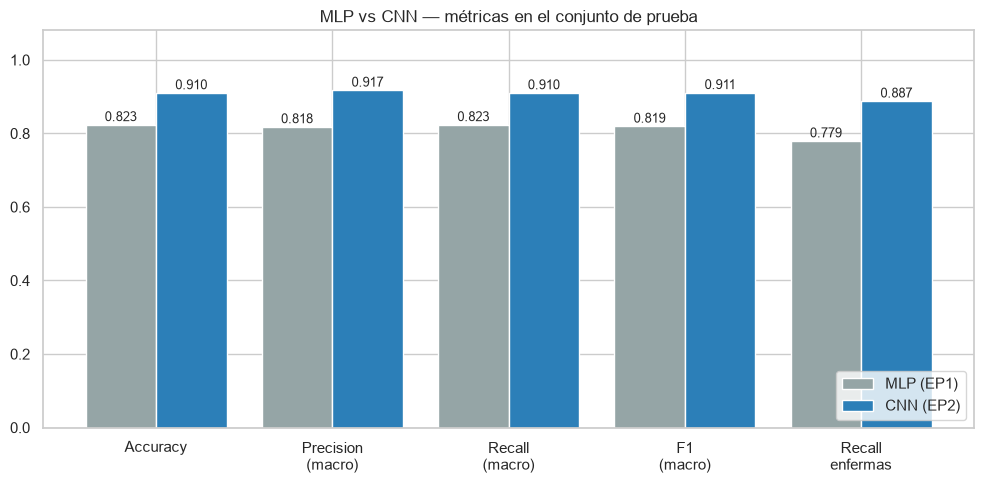

Figura guardada: cnn_07_curvas_mlp_vs_cnn.png


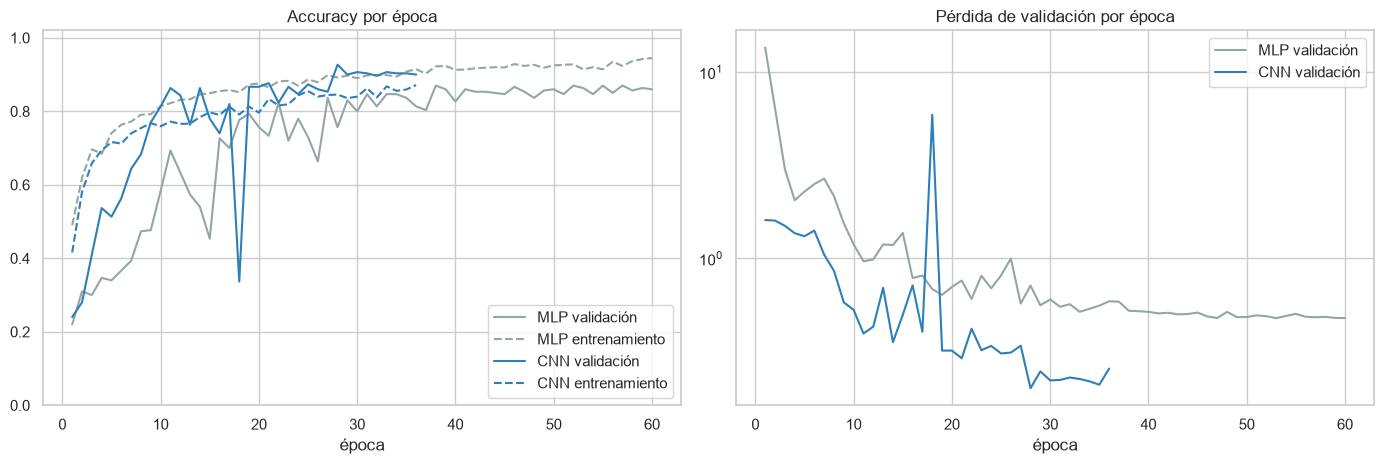

Figura guardada: cnn_07_f1_por_clase.png


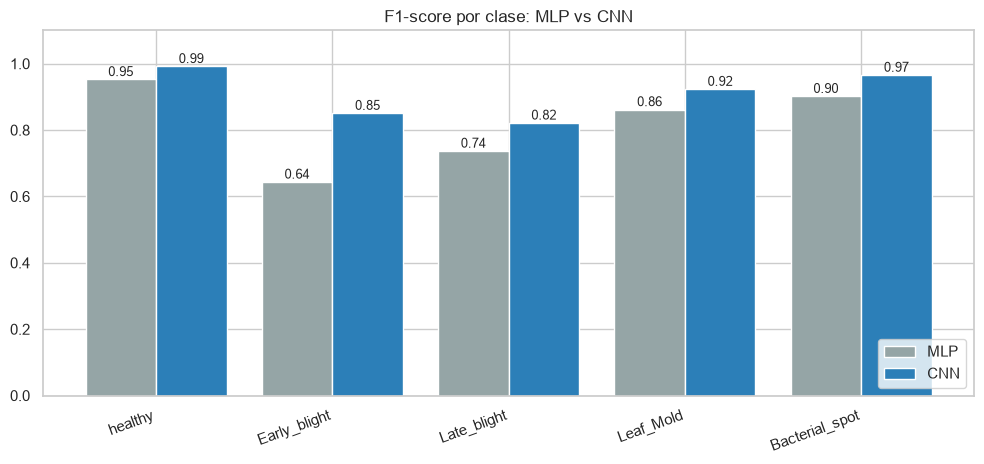

Figura guardada: cnn_07_matrices_confusion.png


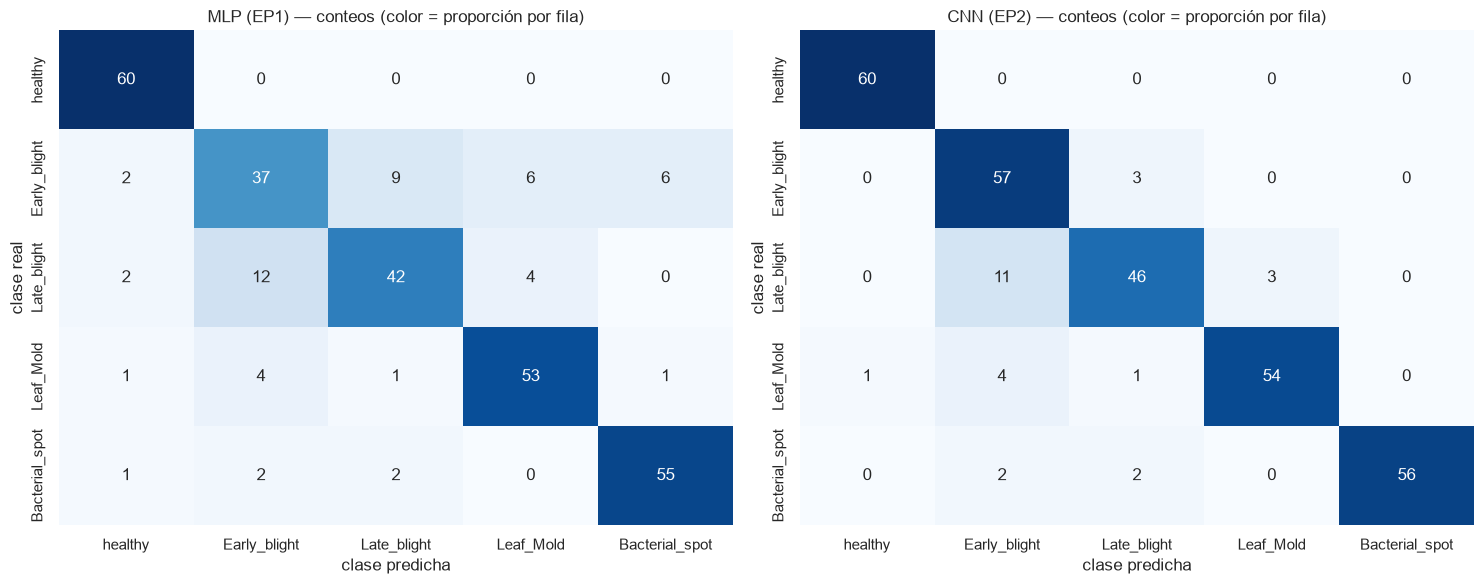

In [31]:
# --- Gráfico 1: métricas globales ---------------------------------------------
nombres_m = ["Accuracy", "Precision\n(macro)", "Recall\n(macro)", "F1\n(macro)", "Recall\nenfermas"]
v_mlp = [MLP_ACC, MLP_PREC, MLP_REC, MLP_F1, MLP_REC_ENF]
v_cnn = [CNN_ACC, CNN_PREC, CNN_REC, CNN_F1, CNN_REC_ENF]
x = np.arange(len(nombres_m))

fig, ax = plt.subplots(figsize=(10, 5))
b1 = ax.bar(x - 0.2, v_mlp, 0.4, label="MLP (EP1)", color="#95a5a6")
b2 = ax.bar(x + 0.2, v_cnn, 0.4, label="CNN (EP2)", color="#2c7fb8")
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"{b.get_height():.3f}",
            ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(nombres_m)
ax.set_ylim(0, 1.08)
ax.set_title("MLP vs CNN — métricas en el conjunto de prueba")
ax.legend(loc="lower right")
plt.tight_layout()
save_fig("cnn_07_comparacion_metricas.png")
plt.show()

# --- Gráfico 2: curvas de aprendizaje de ambos modelos -------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(np.arange(1, len(mlp_hist) + 1), mlp_hist["val_accuracy"], label="MLP validación", color="#95a5a6")
axes[0].plot(np.arange(1, len(mlp_hist) + 1), mlp_hist["accuracy"], "--", label="MLP entrenamiento", color="#95a5a6")
axes[0].plot(epocas, hist["val_accuracy"], label="CNN validación", color="#2c7fb8")
axes[0].plot(epocas, hist["accuracy"], "--", label="CNN entrenamiento", color="#2c7fb8")
axes[0].set_title("Accuracy por época")
axes[0].set_xlabel("época")
axes[0].set_ylim(0, 1.02)
axes[0].legend()

axes[1].plot(np.arange(1, len(mlp_hist) + 1), mlp_hist["val_loss"], label="MLP validación", color="#95a5a6")
axes[1].plot(epocas, hist["val_loss"], label="CNN validación", color="#2c7fb8")
axes[1].set_title("Pérdida de validación por época")
axes[1].set_xlabel("época")
axes[1].set_yscale("log")
axes[1].legend()
plt.tight_layout()
save_fig("cnn_07_curvas_mlp_vs_cnn.png")
plt.show()

# --- Gráfico 3: F1 por clase ---------------------------------------------------
f1_mlp = mlp_por_clase.reindex(CORTO)["f1-score"].to_numpy()   # mismo orden de clases que la CNN
f1_cnn = reporte_df["f1-score"].to_numpy()
x = np.arange(NUM_CLASSES)
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(x - 0.2, f1_mlp, 0.4, label="MLP", color="#95a5a6")
ax.bar(x + 0.2, f1_cnn, 0.4, label="CNN", color="#2c7fb8")
for i in range(NUM_CLASSES):
    ax.text(i + 0.2, f1_cnn[i] + 0.01, f"{f1_cnn[i]:.2f}", ha="center", fontsize=9)
    ax.text(i - 0.2, f1_mlp[i] + 0.01, f"{f1_mlp[i]:.2f}", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(CORTO, rotation=20, ha="right")
ax.set_ylim(0, 1.1)
ax.set_title("F1-score por clase: MLP vs CNN")
ax.legend(loc="lower right")
plt.tight_layout()
save_fig("cnn_07_f1_por_clase.png")
plt.show()

# --- Gráfico 4: matrices de confusión lado a lado -------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, m, titulo in ((axes[0], cm_mlp, "MLP (EP1)"), (axes[1], cm, "CNN (EP2)")):
    mn = m.astype(float) / m.sum(axis=1, keepdims=True)
    sns.heatmap(mn, annot=m, fmt="d", cmap="Blues", cbar=False, vmin=0, vmax=1,
                xticklabels=CORTO, yticklabels=CORTO, ax=ax)
    ax.set_title(f"{titulo} — conteos (color = proporción por fila)")
    ax.set_xlabel("clase predicha")
    ax.set_ylabel("clase real")
plt.tight_layout()
save_fig("cnn_07_matrices_confusion.png")
plt.show()

### 7.4 ¿La diferencia es real o es azar? Prueba de McNemar

Con solo 300 imágenes de prueba, una diferencia de accuracy puede deberse al azar. Como ambos modelos clasificaron **las mismas** imágenes, se usa la **prueba de McNemar exacta**: solo cuentan las imágenes en las que los modelos *discrepan* (uno acierta y el otro falla).

In [32]:
MCNEMAR = None

if y_pred_mlp is not None:
    ok_cnn = (y_pred == y_test)
    ok_mlp = (y_pred_mlp == y_test)
    b = int((ok_cnn & ~ok_mlp).sum())      # CNN acierta, MLP falla
    c = int((~ok_cnn & ok_mlp).sum())      # MLP acierta, CNN falla
    ambos_ok = int((ok_cnn & ok_mlp).sum())
    ambos_mal = int((~ok_cnn & ~ok_mlp).sum())
    p_valor = binomtest(b, b + c, 0.5).pvalue if (b + c) > 0 else 1.0
    MCNEMAR = dict(b=b, c=c, ambos_ok=ambos_ok, ambos_mal=ambos_mal, p=p_valor)

    print(pd.DataFrame(
        [[ambos_ok, c], [b, ambos_mal]],
        index=["MLP acierta", "MLP falla"], columns=["CNN acierta", "CNN falla"]))
    print(f"\nSolo la CNN acierta: {b} | solo el MLP acierta: {c} | p-valor (McNemar exacto): {p_valor:.4f}")
    print("→ diferencia estadísticamente significativa (p < 0,05)" if p_valor < 0.05
          else "→ diferencia NO significativa al 5 %: con esta muestra no se puede descartar el azar")
else:
    print("No hay predicciones del MLP para la prueba pareada.")

             CNN acierta  CNN falla
MLP acierta          237         10
MLP falla             36         17

Solo la CNN acierta: 36 | solo el MLP acierta: 10 | p-valor (McNemar exacto): 0.0002
→ diferencia estadísticamente significativa (p < 0,05)


**Lectura de la comparación (7.3 y 7.4).**

- **Desempeño:** +8,7 pp de accuracy y +9,1 pp de F1 macro. La CNN mejora en las cinco clases; la mayor ganancia es **Early_blight (F1 0,64 → 0,85)**, justamente la clase cuya identidad depende de la *forma* de la lesión.
- **¿Es real?** De las 300 imágenes, 237 las aciertan ambos modelos y 17 las fallan ambos. En las 46 donde discrepan, la CNN acierta 36 y el MLP 10: **p = 0,0002**. La mejora no se explica por el azar de la muestra.
- **Parámetros:** 1,14 M frente a 3,18 M (**36 %**). La CNN es más pequeña *y* mejor: sus filtros (93 mil parámetros) se comparten en toda la imagen, mientras que el MLP gasta 3,1 M solo en conectar cada píxel con su primera capa.
- **Tiempo:** la CNN es **~3,4 veces más lenta por época** (0,88 s frente a 0,26 s, en CPU), porque cada filtro recorre toda la imagen. Como converge antes (36 épocas frente a 59), el tiempo total es ~2 veces mayor (31,6 s frente a 15,1 s). Los tiempos varían un poco entre ejecuciones; la proporción se mantiene. Con GPU la diferencia se reduce.
- **Generalización:** brecha 0,061 frente a 0,148. Por coincidencia, ambos modelos alcanzan exactamente 0,9714 de accuracy en entrenamiento (1.360 de 1.400 imágenes). La diferencia está en la prueba: con imágenes nuevas la CNN pierde 6 pp y el MLP 15 pp.


### 7.5 Ventajas y desventajas de cada arquitectura

| Aspecto | MLP | CNN |
|---|---|---|
| **Entrada** | Vector aplanado: pierde la vecindad entre píxeles | Tensor 64×64×3: conserva la estructura espacial |
| **Extracción de características** | No hay una explícita; aprende un peso por píxel y neurona | Filtros locales **compartidos** que recorren toda la imagen; jerarquía borde → textura → parte |
| **Parámetros** | Crecen con el tamaño de la imagen (la 1ª capa densa concentra casi todo) | Los filtros no dependen del tamaño de la imagen; el peso se concentra en la capa densa final |
| **Invarianza a traslación** | Ninguna: la misma lesión en otra posición es "otro patrón" | Parcial (pesos compartidos + pooling) |
| **Costo de cómputo** | Pocas operaciones por época | Más operaciones por época (la convolución recorre toda la imagen); la GPU ayuda mucho |
| **Interpretabilidad** | Limitada | Feature maps y Grad-CAM muestran *dónde* mira |
| **Riesgo** | Memoriza con pocos datos (muchos parámetros por imagen) | También puede sobreajustar; sensible a hiperparámetros y a sesgos del dataset (p. ej., el fondo) |

La tabla 7.3 y la prueba 7.4 dicen **cuánto** de esto se cumplió en este experimento concreto.

---

## 8. Feature Maps, filtros y mapas de activación (Grad-CAM)

Hasta aquí las métricas responden *"¿qué tan bien clasifica?"*. Esta sección responde *"¿qué aprendió y en qué se fija?"*.

### 8.1 Filtros aprendidos en la primera capa

Cada filtro de `conv1` es un pequeño patrón 3×3×3 (RGB) aprendido durante el entrenamiento — el equivalente automático de los kernels manuales (Sobel, blur, sharpen) vistos en clase.

Figura guardada: cnn_08_filtros_conv1.png


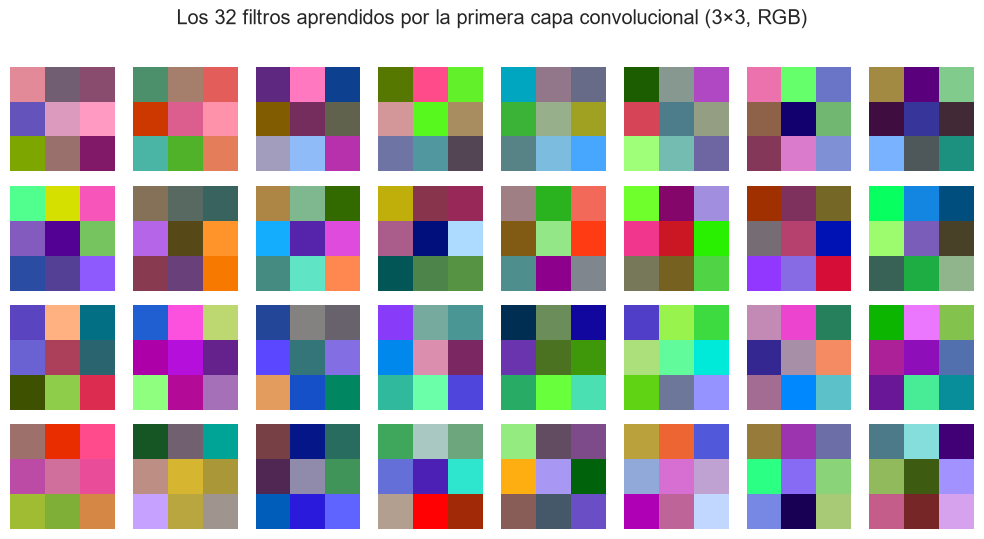

In [33]:
pesos_conv1 = cnn.get_layer("conv1").get_weights()[0]            # (3, 3, 3, 32)
n_f = pesos_conv1.shape[-1]

fig, axes = plt.subplots(4, 8, figsize=(10, 5.4))
for i, ax in enumerate(axes.flat):
    if i < n_f:
        f = pesos_conv1[:, :, :, i]
        f = (f - f.min()) / (f.max() - f.min() + 1e-8)           # normaliza para visualizar
        ax.imshow(f, interpolation="nearest")
    ax.axis("off")
plt.suptitle("Los 32 filtros aprendidos por la primera capa convolucional (3×3, RGB)", y=1.0)
plt.tight_layout()
save_fig("cnn_08_filtros_conv1.png")
plt.show()

### 8.2 Feature Maps: qué responde cada capa

El **filtro** es fijo (lo aprendido); el **feature map** es su respuesta frente a una imagen concreta. Se muestran los primeros 8 mapas de cada bloque convolucional (después de ReLU) para una hoja del conjunto de prueba, para ver cómo evoluciona la representación al aumentar la profundidad.

Figura guardada: cnn_08_feature_maps_early_blight.png


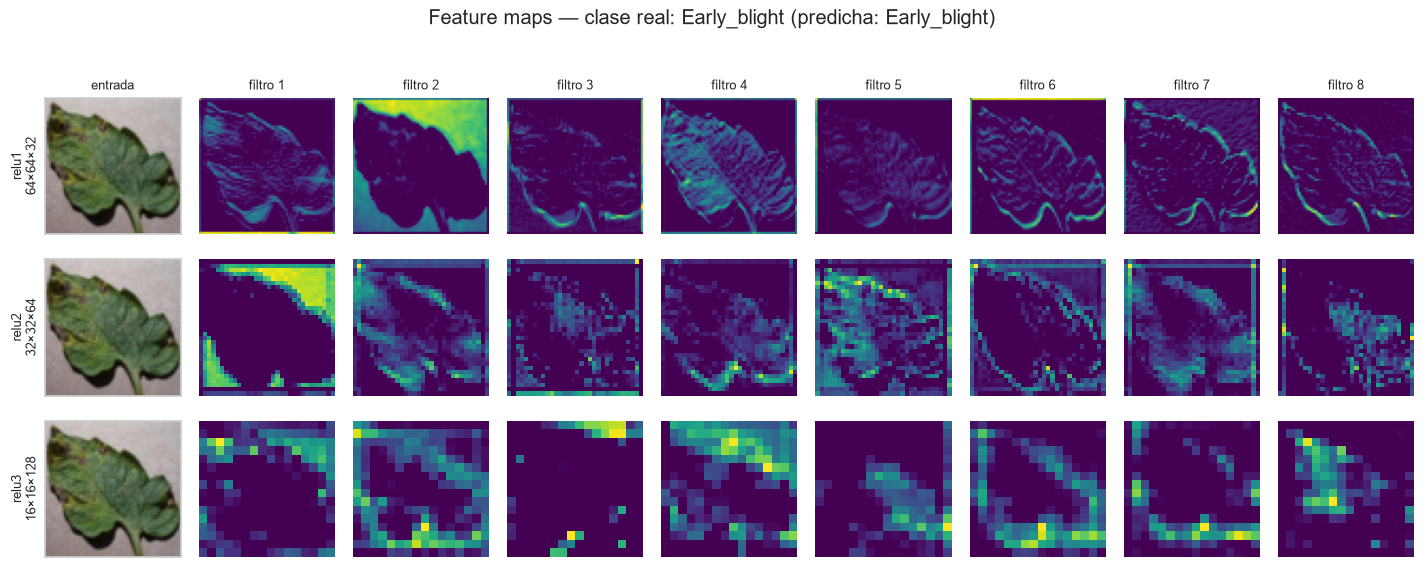

Figura guardada: cnn_08_feature_maps_healthy.png


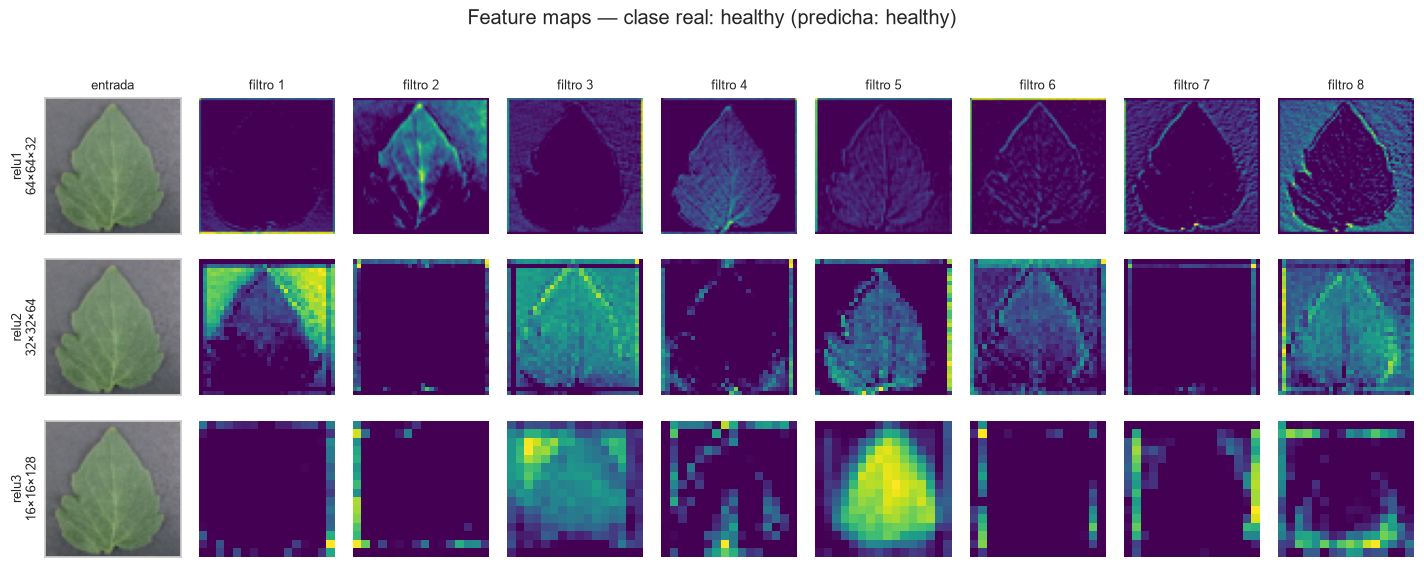

In [34]:
CAPAS_FM = ["relu1", "relu2", "relu3"]
ULTIMA_CONV = CAPAS_FM[-1]


def primer_indice(clase_id, solo_aciertos=True):
    """Primera imagen de prueba de esa clase (preferiblemente bien clasificada)."""
    base = np.where(y_test == clase_id)[0]
    if solo_aciertos:
        buenos = [i for i in base if y_pred[i] == clase_id]
        if buenos:
            return int(buenos[0])
    return int(base[0])


def mostrar_feature_maps(idx, capas=CAPAS_FM, n_mapas=8, archivo=None):
    x = X_test[idx:idx + 1]
    fm_model = Model(inputs=cnn.inputs, outputs=[cnn.get_layer(c).output for c in capas])
    salidas = fm_model(x, training=False)

    fig, axes = plt.subplots(len(capas), n_mapas + 1, figsize=(1.6 * (n_mapas + 1), 1.9 * len(capas)))
    for r, (nombre, fm) in enumerate(zip(capas, salidas)):
        fm = fm.numpy()[0]                                       # (alto, ancho, filtros)
        axes[r, 0].imshow(x[0])
        axes[r, 0].set_title("entrada" if r == 0 else "", fontsize=9)
        axes[r, 0].set_ylabel(f"{nombre}\n{fm.shape[0]}×{fm.shape[1]}×{fm.shape[2]}", fontsize=9)
        axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([])
        for k in range(n_mapas):
            axes[r, k + 1].imshow(fm[:, :, k], cmap="viridis")
            axes[r, k + 1].axis("off")
            if r == 0:
                axes[r, k + 1].set_title(f"filtro {k + 1}", fontsize=9)
    plt.suptitle(f"Feature maps — clase real: {CORTO[y_test[idx]]} "
                 f"(predicha: {CORTO[y_pred[idx]]})", y=1.02)
    plt.tight_layout()
    if archivo:
        save_fig(archivo)
    plt.show()


# Una hoja enferma con forma de lesión característica y una sana
for clase in ("Tomato_Early_blight", "Tomato_healthy"):
    mostrar_feature_maps(primer_indice(LABEL_TO_ID[clase]),
                         archivo=f"cnn_08_feature_maps_{clase.replace('Tomato_', '').lower()}.png")

**Cómo leerlos.** Valores altos (colores claros) indican que el patrón que busca ese filtro está presente en esa zona. Al avanzar de `relu1` a `relu3`, el tamaño espacial baja (64 → 32 → 16) y la profundidad sube (32 → 64 → 128 filtros).

**Lo que se observa en este modelo:**

- **`relu1` (64×64×32):** los mapas todavía se parecen a la hoja. Hay filtros que responden al **contorno** de la hoja y del tallo, otros a las **nervaduras**, y al menos uno que se activa solo en el **fondo** y queda apagado sobre la hoja: la red aprendió por sí sola a separar figura y fondo.
- **`relu2` (32×32×64):** las activaciones dejan de seguir píxeles y marcan **regiones**: zonas con textura de lesión, bordes gruesos y manchas.
- **`relu3` (16×16×128):** mapas gruesos y abstractos; cada celda resume un campo receptivo de 18×18 px. En la hoja sana, un filtro reproduce la **silueta completa de la hoja**. En la hoja con Early_blight, varios filtros se encienden en las zonas con **manchas oscuras**. Ya no responden a "un borde", sino a "un patrón de lesión en esta zona".
- Varios filtros profundos se activan en el **marco de la imagen**. Es un efecto del `padding="same"` (relleno con ceros en los bordes) que la red aprende a reconocer, y anticipa que el borde puede influir en la decisión (ver 8.3 y 9.5).
- Algunos mapas quedan casi apagados: ese filtro no encontró su patrón en esta imagen (con ReLU, lo ausente vale 0).

Esa es la **extracción automática de características**: nadie programó detectores de borde ni de mancha, las convoluciones los aprendieron a partir de las etiquetas. El MLP no puede hacerlo porque al aplanar la imagen pierde qué píxel es vecino de cuál.

> **Para la defensa:** la primera capa detecta rasgos locales simples; las capas profundas combinan esos rasgos en patrones más complejos (la jerarquía bordes → texturas → partes). Cada neurona de `relu3` integra un campo receptivo de 18×18 px, frente a 3×3 en `relu1` (sección 4.3).

### 8.3 Mapa de activación por clase: Grad-CAM

**Grad-CAM** responde *¿qué regiones de la imagen empujaron la decisión hacia una clase?* Pasos: (1) se toman los feature maps de la última capa convolucional; (2) se calcula el gradiente de la clase respecto de cada mapa y se promedia en el espacio → un peso por filtro; (3) se combinan los mapas con esos pesos y se aplica ReLU (solo contribuciones positivas); (4) se amplía al tamaño de la imagen y se superpone como mapa de calor.

Se deriva sobre el **logit** de la clase (antes del softmax): si el softmax satura (probabilidad ≈ 1) su gradiente se anula y el mapa sale vacío o ruidoso.


In [35]:
grad_model = Model(
    inputs=cnn.inputs,
    outputs=[cnn.get_layer(ULTIMA_CONV).output, cnn.get_layer("logits").output],
)


def gradcam(img, clase=None):
    """Devuelve (mapa 64×64 en [0,1], clase usada). Si clase es None usa la predicha."""
    x = tf.convert_to_tensor(img[None, ...], dtype=tf.float32)
    with tf.GradientTape() as tape:
        conv_out, logits = grad_model(x, training=False)
        if clase is None:
            clase = int(tf.argmax(logits[0]))
        score = logits[:, clase]
    grads = tape.gradient(score, conv_out)                       # (1, h, w, filtros)
    pesos = tf.reduce_mean(grads, axis=(0, 1, 2))                # un peso por filtro
    cam = tf.reduce_sum(conv_out[0] * pesos, axis=-1)            # combinación ponderada
    cam = tf.nn.relu(cam)                                        # solo contribuciones positivas
    cam = tf.image.resize(cam[..., tf.newaxis], IMG_SIZE, method="bilinear")[..., 0].numpy()
    cam = cam / (cam.max() + 1e-8)
    return cam, clase


def superponer(ax, img, cam, titulo="", alpha=0.45):
    ax.imshow(img)
    ax.imshow(cam, cmap="jet", alpha=alpha, vmin=0, vmax=1)
    ax.set_title(titulo, fontsize=8)
    ax.axis("off")


# Prueba rápida con una imagen: el mapa no debe ser todo ceros
cam_t, _ = gradcam(X_test[primer_indice(1)])
print("Grad-CAM de prueba → forma:", cam_t.shape, "| máx:", round(float(cam_t.max()), 3),
      "| media:", round(float(cam_t.mean()), 3))

Grad-CAM de prueba → forma: (64, 64) | máx: 1.0 | media: 0.238


Figura guardada: cnn_08_gradcam_por_clase.png


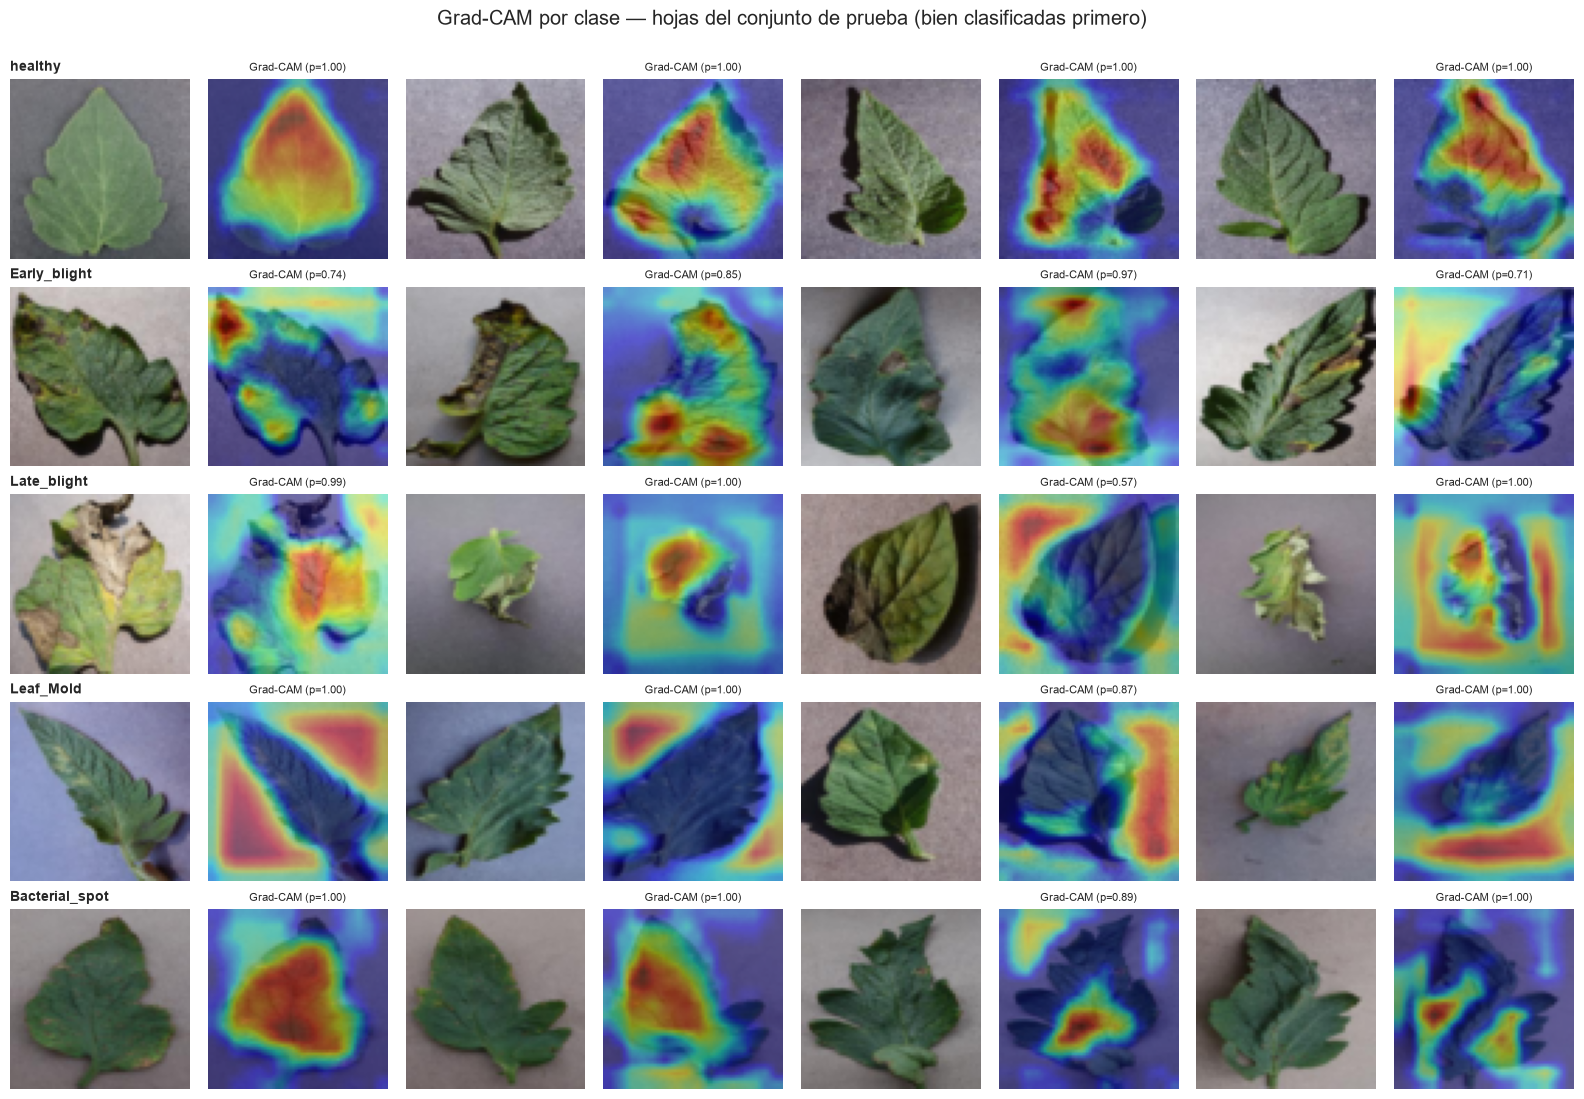

In [36]:
# --- Un Grad-CAM por clase: 4 hojas bien clasificadas de cada clase ---------------
N_POR_CLASE = 4
fig, axes = plt.subplots(NUM_CLASSES, N_POR_CLASE * 2, figsize=(2.0 * N_POR_CLASE * 2, 2.2 * NUM_CLASSES))
for c in range(NUM_CLASSES):
    de_la_clase = list(np.where(y_test == c)[0])
    idxs = [i for i in de_la_clase if y_pred[i] == c]
    idxs = (idxs + [i for i in de_la_clase if y_pred[i] != c])[:N_POR_CLASE]   # si faltan aciertos, se completa
    for k in range(N_POR_CLASE):
        ax_o, ax_g = axes[c, 2 * k], axes[c, 2 * k + 1]
        if k < len(idxs):
            i = idxs[k]
            cam_i, _ = gradcam(X_test[i], clase=c)
            ax_o.imshow(X_test[i]); ax_o.axis("off")
            marca = "" if y_pred[i] == c else "  [no acertada]"
            superponer(ax_g, X_test[i], cam_i, f"Grad-CAM (p={y_prob[i, c]:.2f}){marca}")
            if k == 0:
                ax_o.set_title(CORTO[c], loc="left", fontsize=10, fontweight="bold")
        else:
            ax_o.axis("off"); ax_g.axis("off")
plt.suptitle("Grad-CAM por clase — hojas del conjunto de prueba (bien clasificadas primero)", y=1.0)
plt.tight_layout()
save_fig("cnn_08_gradcam_por_clase.png")
plt.show()

Figura guardada: cnn_08_gradcam_promedio.png


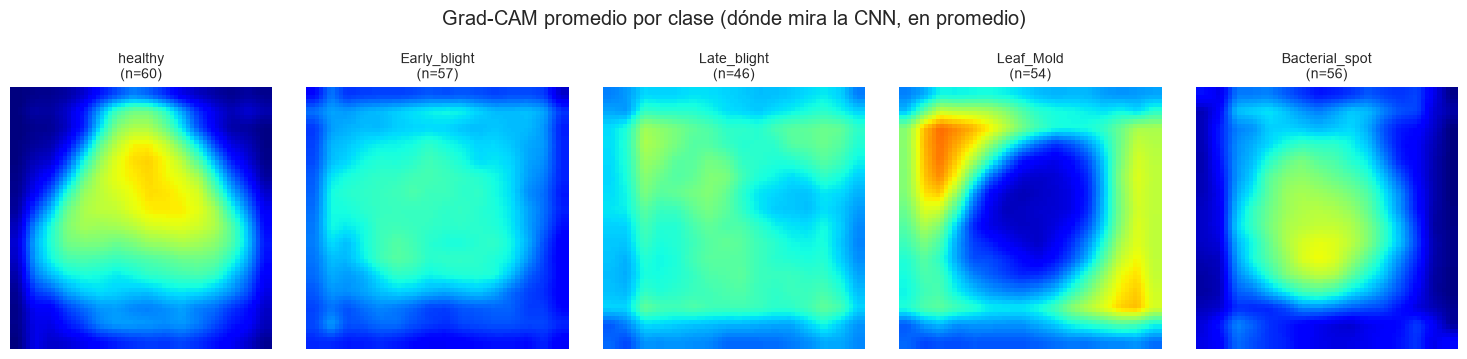

In [37]:
# --- Mapa de activación PROMEDIO por clase (sobre todas las aciertos de la prueba) ---
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(3.0 * NUM_CLASSES, 3.4))
CAM_PROMEDIO = {}
for c in range(NUM_CLASSES):
    idxs = [i for i in np.where(y_test == c)[0] if y_pred[i] == c]
    nota = ""
    if not idxs:                                   # clase sin aciertos: se promedian todas sus imágenes
        idxs = list(np.where(y_test == c)[0])
        nota = " [sin aciertos]"
    mapas = np.stack([gradcam(X_test[i], clase=c)[0] for i in idxs])
    CAM_PROMEDIO[c] = mapas.mean(axis=0)
    axes[c].imshow(CAM_PROMEDIO[c], cmap="jet", vmin=0, vmax=1)
    axes[c].set_title(f"{CORTO[c]}\n(n={len(idxs)}){nota}", fontsize=10)
    axes[c].axis("off")
plt.suptitle("Grad-CAM promedio por clase (dónde mira la CNN, en promedio)", y=1.05)
plt.tight_layout()
save_fig("cnn_08_gradcam_promedio.png")
plt.show()

**Cómo interpretar un Grad-CAM**

- Zona **cálida (rojo/amarillo)** = región que más aportó a que la red decidiera esa clase.
- Si el calor cae **sobre la lesión o la hoja**, la red está usando evidencia relevante (señal buena).
- Si cae sobre el **fondo, el borde de la imagen o zonas sin lesión**, la red puede estar apoyándose en un atajo (p. ej., el fondo uniforme o la iluminación del laboratorio) y no en la enfermedad.
- Un mapa **difuso** que cubre toda la hoja suele indicar que la clase se reconoce por el aspecto general (color/textura) más que por una lesión puntual.
- Limitación: con 16×16 de resolución en `relu3` el mapa es *grueso*; muestra regiones, no contornos.

**Lo que muestran los Grad-CAM de este modelo** (`cnn_08_gradcam_por_clase.png` y `cnn_08_gradcam_promedio.png`):

| Clase | Dónde mira la red | Lectura |
|---|---|---|
| **healthy** | La hoja completa; el fondo queda frío | Correcto: "sana" es la ausencia de lesión en toda la superficie, así que la evidencia es la hoja entera. |
| **Bacterial_spot** | Interior de la hoja, sobre la zona con puntos oscuros | Correcto: usa la lesión. |
| **Early_blight** | Las **lesiones** concretas (manchas oscuras, a menudo en el borde de la hoja) | Es la clase donde mejor se ve que la red usa la enfermedad. |
| **Late_blight** | Mixto: sobre la zona necrosada cuando la lesión es grande, pero en otras hojas se reparte hacia el borde de la imagen | Sin un patrón estable: coherente con ser la clase de menor recall. |
| **Leaf_Mold** | **El fondo**, no la hoja; el mapa promedio tiene el centro frío y las esquinas calientes | **Atajo:** las fotos de Leaf_Mold tienen un fondo más azulado que el resto (ya visible en el EDA de color, sección 2.5). La red acierta, pero en parte por una razón equivocada. Se mide en la sección 9.5. |

> **Para la defensa:** Grad-CAM permite auditar *por qué* acierta la red, no solo *cuánto*. Un F1 de 0,92 en Leaf_Mold no garantiza que el modelo funcione con fotos de campo, donde el fondo es otro.

---

## 9. Análisis de resultados y errores

### 9.1 Confianza de las predicciones

Aciertos: 273 de 300 (91.0%)
Errores : 27 de 300 (9.0%)
Confianza media en aciertos: 0.929
Confianza media en errores : 0.652


Figura guardada: cnn_09_confianza.png


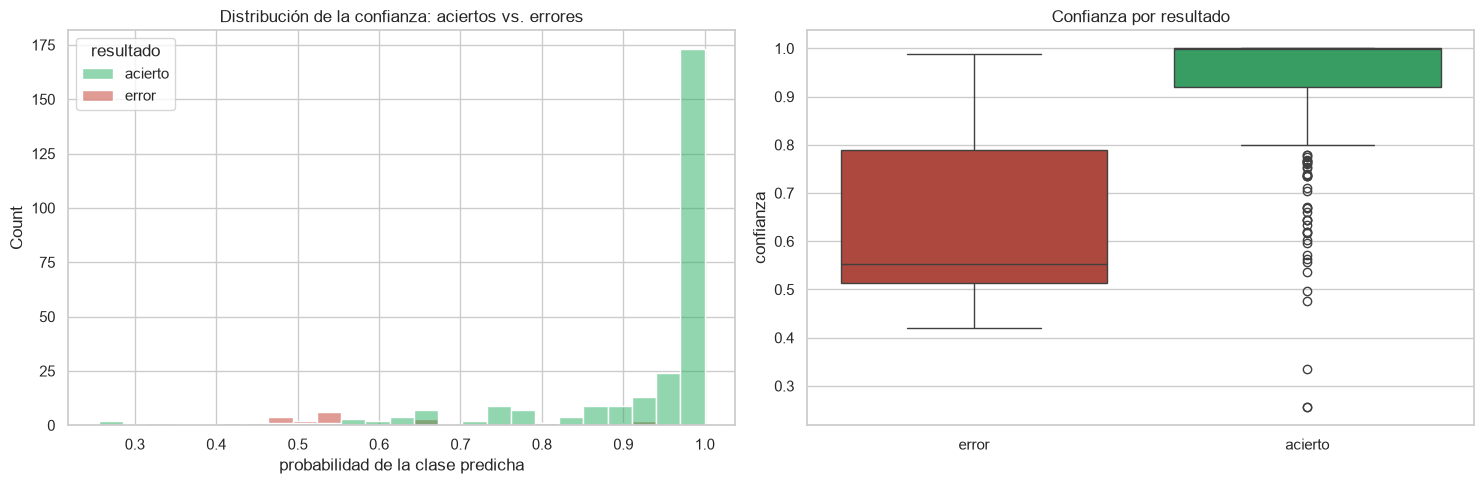


Errores con confianza ≥ 0,90 (el modelo 'seguro' se equivocó): 5


In [38]:
resultados = test_df[["path_rel", "label", "label_id"]].copy().reset_index(drop=True)
resultados["predicho"] = [ID_TO_LABEL[i] for i in y_pred]
resultados["confianza"] = y_prob.max(axis=1)
resultados["correcto"] = (y_test == y_pred)
resultados["resultado"] = np.where(resultados["correcto"], "acierto", "error")
PALETA = {"acierto": "#27ae60", "error": "#c0392b"}

aciertos = resultados[resultados["correcto"]]
errores = resultados[~resultados["correcto"]]
N_ERRORES = len(errores)
CONF_ACIERTOS = float(aciertos["confianza"].mean())
CONF_ERRORES = float(errores["confianza"].mean()) if N_ERRORES else float("nan")

print(f"Aciertos: {len(aciertos)} de {len(resultados)} ({len(aciertos) / len(resultados):.1%})")
print(f"Errores : {N_ERRORES} de {len(resultados)} ({N_ERRORES / len(resultados):.1%})")
print(f"Confianza media en aciertos: {CONF_ACIERTOS:.3f}")
print(f"Confianza media en errores : {CONF_ERRORES:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(data=resultados, x="confianza", hue="resultado", bins=25, ax=axes[0], palette=PALETA)
axes[0].set_title("Distribución de la confianza: aciertos vs. errores")
axes[0].set_xlabel("probabilidad de la clase predicha")
if N_ERRORES:
    sns.boxplot(data=resultados, x="resultado", y="confianza", order=["error", "acierto"],
                hue="resultado", legend=False, ax=axes[1], palette=PALETA)
axes[1].set_title("Confianza por resultado")
axes[1].set_xlabel("")
plt.tight_layout()
save_fig("cnn_09_confianza.png")
plt.show()

errores_confiados = errores[errores["confianza"] >= 0.90]
print(f"\nErrores con confianza ≥ 0,90 (el modelo 'seguro' se equivocó): {len(errores_confiados)}")

**Lectura:** la confianza media es **0,93 en los aciertos y 0,65 en los errores**. Cuando la red se equivoca suele dudar, así que un umbral de confianza permitiría derivar a revisión humana gran parte de los errores. Pero **5 errores tienen confianza ≥ 0,90**: hay errores "seguros" que ningún umbral atraparía (se analizan en 9.3).


### 9.2 Ejemplos correctamente clasificados

Figura guardada: cnn_09_aciertos.png


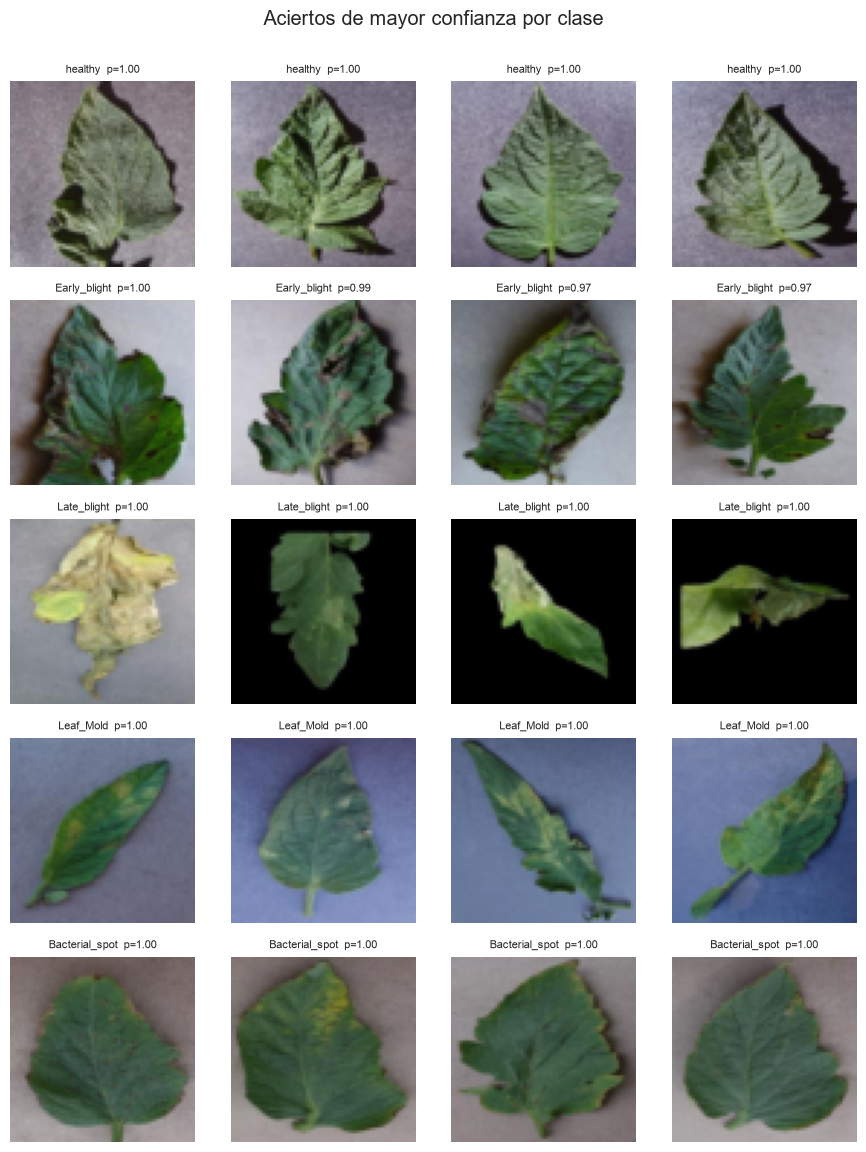

In [39]:
fig, axes = plt.subplots(NUM_CLASSES, 4, figsize=(9, 2.3 * NUM_CLASSES))
for c in range(NUM_CLASSES):
    idxs = [i for i in np.where(y_test == c)[0] if y_pred[i] == c]
    idxs = sorted(idxs, key=lambda i: -y_prob[i, c])[:4]            # los más confiados
    for k in range(4):
        ax = axes[c, k]
        if k < len(idxs):
            ax.imshow(X_test[idxs[k]])
            ax.set_title(f"{CORTO[c]}  p={y_prob[idxs[k], c]:.2f}", fontsize=8)
        ax.axis("off")
plt.suptitle("Aciertos de mayor confianza por clase", y=1.0)
plt.tight_layout()
save_fig("cnn_09_aciertos.png")
plt.show()

### 9.3 Ejemplos mal clasificados — y dónde miraba la red

Para cada error (de mayor a menor confianza) se muestra la imagen, el Grad-CAM de la clase que **predijo** y el de la clase **real**. Comparar ambos ayuda a distinguir un error por *ambigüedad visual* de uno por *atajo* (la red mira donde no debe).

Figura guardada: cnn_09_errores_gradcam.png


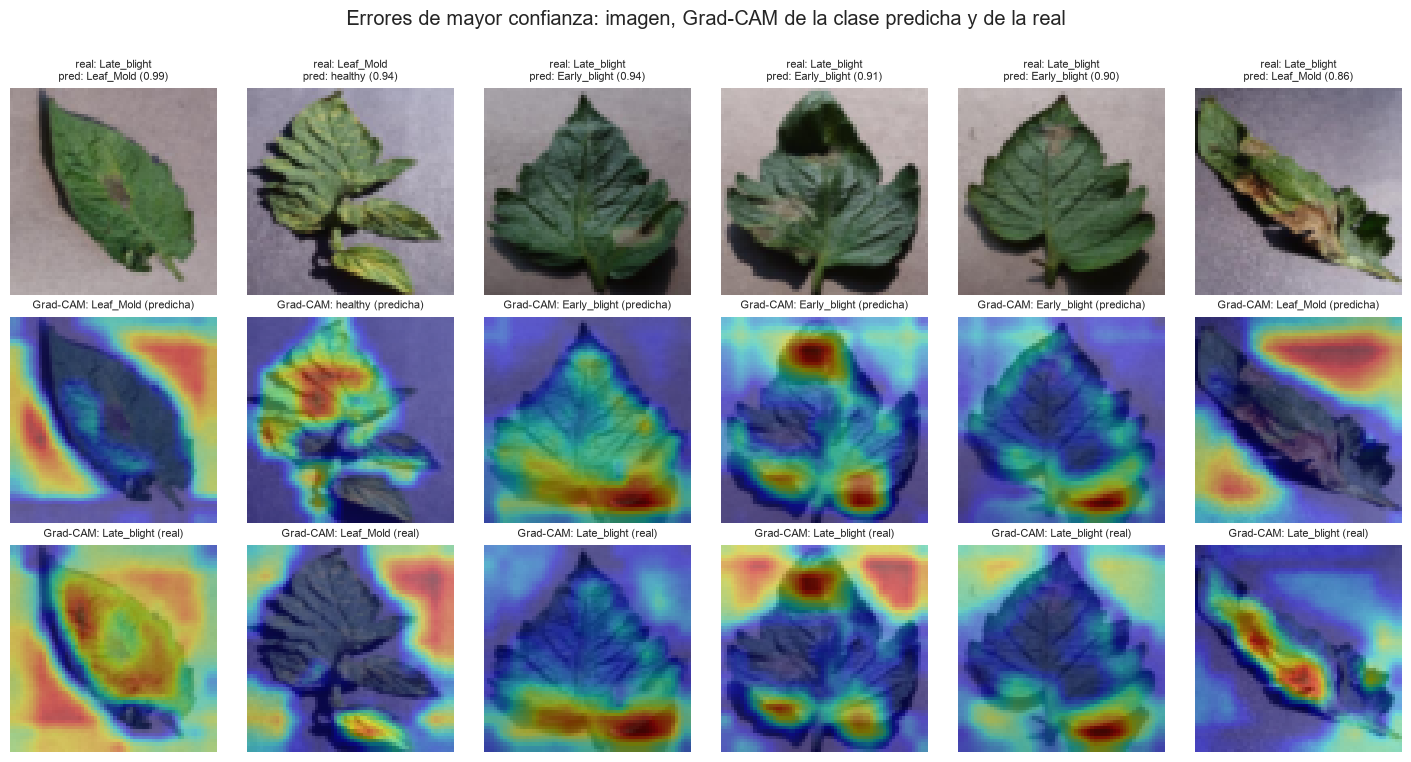

In [40]:
def mostrar_errores_gradcam(n_max=6, archivo="cnn_09_errores_gradcam.png"):
    if N_ERRORES == 0:
        print("La CNN no cometió errores en la prueba: no hay casos que mostrar.")
        return
    orden = errores.sort_values("confianza", ascending=False).head(n_max)
    idxs = orden.index.to_numpy()
    n = len(idxs)
    fig, axes = plt.subplots(3, n, figsize=(2.4 * n, 7.6), squeeze=False)
    for k, i in enumerate(idxs):
        real, pred = int(y_test[i]), int(y_pred[i])
        axes[0, k].imshow(X_test[i])
        axes[0, k].set_title(f"real: {CORTO[real]}\npred: {CORTO[pred]} ({y_prob[i, pred]:.2f})", fontsize=8)
        axes[0, k].axis("off")
        cam_p, _ = gradcam(X_test[i], clase=pred)
        superponer(axes[1, k], X_test[i], cam_p, f"Grad-CAM: {CORTO[pred]} (predicha)")
        cam_r, _ = gradcam(X_test[i], clase=real)
        superponer(axes[2, k], X_test[i], cam_r, f"Grad-CAM: {CORTO[real]} (real)")
    plt.suptitle("Errores de mayor confianza: imagen, Grad-CAM de la clase predicha y de la real", y=1.0)
    plt.tight_layout()
    save_fig(archivo)
    plt.show()


mostrar_errores_gradcam()

**Lectura de los errores de mayor confianza.**

- **Late_blight → Leaf_Mold** (confianza 0,99 y 0,86): el Grad-CAM de la clase predicha cae sobre el **fondo**. Es el mismo atajo de la sección 8.3: hojas fotografiadas con un fondo parecido al de Leaf_Mold.
- **Late_blight → Early_blight** (0,94; 0,91; 0,90): los Grad-CAM de ambas clases señalan **la misma lesión**. La red ve la mancha correcta, pero no logra distinguir de qué tizón se trata: es un error por **ambigüedad visual** a 64×64, no un atajo.
- **Leaf_Mold → healthy** (0,94): el único falso negativo crítico. Es una hoja con manchas amarillas difusas (síntoma temprano de Leaf_Mold) y el Grad-CAM de "sana" cubre la hoja: una lesión incipiente que se confunde con tejido sano.

Son dos tipos de error con soluciones distintas: el atajo de fondo se corrige con **datos** (fondos variados, recorte de la hoja); la ambigüedad entre tizones, con **más resolución** o un modelo preentrenado.


### 9.4 Clases con mayor dificultad y confusiones

Se contrasta con el MLP: ¿la CNN resolvió las confusiones que el MLP no podía (por ejemplo `Early_blight` ↔ `Late_blight`, que solo se distinguen por la forma de la lesión)?

In [41]:
pares = []
for r_ in range(NUM_CLASSES):
    for c_ in range(NUM_CLASSES):
        if r_ != c_ and (cm[r_, c_] > 0 or cm_mlp[r_, c_] > 0):
            pares.append({"real → predicha": f"{CORTO[r_]} → {CORTO[c_]}",
                          "MLP": int(cm_mlp[r_, c_]), "CNN": int(cm[r_, c_]),
                          "cambio": int(cm[r_, c_] - cm_mlp[r_, c_])})
tabla_pares = (pd.DataFrame(pares)
               .assign(total=lambda d: d["MLP"] + d["CNN"])
               .sort_values("total", ascending=False)
               .drop(columns="total").head(8).reset_index(drop=True))
print("Confusiones más frecuentes (conteos en la prueba; 'cambio' < 0 = la CNN las redujo)")
display(tabla_pares)

dificultad = pd.DataFrame({
    "clase": CORTO,
    "F1 MLP": f1_mlp.round(3),
    "F1 CNN": f1_cnn.round(3),
    "Δ F1": (f1_cnn - f1_mlp).round(3),
    "recall CNN": recall_por_clase.round(3),
}).sort_values("F1 CNN").reset_index(drop=True)
print("\nClases ordenadas de mayor a menor dificultad para la CNN:")
display(dificultad)

# Error más costoso: enferma clasificada como sana
fn = resultados[(resultados["label_id"] != ID_SANA) & (resultados["predicho"] == "Tomato_healthy")]
print(f"\nEnfermas clasificadas como sanas — CNN: {len(fn)} de {N_ENFERMAS_TEST} | MLP: {MLP_FN_CRIT} de {MLP_N_ENFERMAS}")
if len(fn):
    display(fn[["label", "predicho", "confianza"]].sort_values("confianza", ascending=False).head(10))

Confusiones más frecuentes (conteos en la prueba; 'cambio' < 0 = la CNN las redujo)


,real → predicha,MLP,CNN,cambio
0,Late_blight → Early_blight,12,11,-1
1,Early_blight → Late_blight,9,3,-6
2,Leaf_Mold → Early_blight,4,4,0
3,Late_blight → Leaf_Mold,4,3,-1
4,Early_blight → Bacterial_spot,6,0,-6
5,Early_blight → Leaf_Mold,6,0,-6
6,Bacterial_spot → Early_blight,2,2,0
7,Bacterial_spot → Late_blight,2,2,0



Clases ordenadas de mayor a menor dificultad para la CNN:


,clase,F1 MLP,F1 CNN,Δ F1,recall CNN
0,Late_blight,0.737,0.821,0.085,0.767
1,Early_blight,0.644,0.851,0.207,0.950
2,Leaf_Mold,0.862,0.923,0.061,0.900
3,Bacterial_spot,0.902,0.966,0.064,0.933
4,healthy,0.952,0.992,0.039,1.000



Enfermas clasificadas como sanas — CNN: 1 de 240 | MLP: 6 de 240


,label,predicho,confianza
36,Tomato_Leaf_Mold,Tomato_healthy,0.944972


**Lectura:** la CNN redujo casi todas las confusiones del MLP. Early_blight dejó de confundirse con Bacterial_spot (6 → 0) y con Leaf_Mold (6 → 0), y mucho menos con Late_blight (9 → 3). La que **no** se resolvió es **Late_blight → Early_blight (12 → 11)**: es el par más parecido visualmente (ver 2.5) y su diferencia depende de detalles finos que se pierden a 64×64. Por eso Late_blight pasa a ser la clase más difícil (F1 0,82), aunque también mejoró respecto del MLP (0,74). La mayor mejora fue Early_blight (+0,21 de F1).


### 9.5 ¿La CNN usa el fondo como atajo?

Los Grad-CAM de la sección 8 sugieren que en algunas clases la red mira el **fondo** y no la hoja. Para no quedarse en una impresión visual, se mide con dos números sobre el conjunto de prueba:

1. **Color medio del marco exterior** de la imagen (8 px por lado). En PlantVillage la hoja suele estar centrada, así que el marco es mayoritariamente fondo.
2. **Porcentaje de la activación Grad-CAM que cae en ese marco.** El marco ocupa el 43,75 % del área. Como la hoja está al centro, una clase que se reconoce por la hoja debería quedar **muy por debajo** de ese valor. Superarlo (más atención en el borde que si la atención fuera uniforme) es un indicio de que la red se apoya en el fondo.


In [42]:
BORDE = 8
marco = np.ones(IMG_SIZE, dtype=bool)
marco[BORDE:-BORDE, BORDE:-BORDE] = False
AREA_MARCO = marco.mean()                          # 0,4375

filas_fondo = []
for c in range(NUM_CLASSES):
    idxs = np.where(y_test == c)[0]
    rgb = X_test[idxs][:, marco, :].reshape(-1, 3).mean(axis=0) * 255
    cam_c = CAM_PROMEDIO[c]                        # Grad-CAM promedio de la sección 8.3
    filas_fondo.append({
        "clase": CORTO[c],
        "R fondo": round(float(rgb[0]), 1), "G fondo": round(float(rgb[1]), 1), "B fondo": round(float(rgb[2]), 1),
        "B − R": round(float(rgb[2] - rgb[0]), 1),
        "% Grad-CAM en el marco": round(float(100 * cam_c[marco].sum() / cam_c.sum()), 1),
    })
fondo_df = pd.DataFrame(filas_fondo)

mas = fondo_df.loc[fondo_df["% Grad-CAM en el marco"].idxmax()]
CLASE_ATAJO = mas["clase"] if mas["% Grad-CAM en el marco"] > 100 * AREA_MARCO else None

print(f"Área del marco: {AREA_MARCO:.2%} de la imagen (valor esperado si la atención fuera uniforme)")
print(f"Clase con más atención en el marco: {mas['clase']} ({mas['% Grad-CAM en el marco']:.1f} %)")
print(f"Clase con el fondo más azulado    : {fondo_df.loc[fondo_df['B − R'].idxmax(), 'clase']}")
print("→ Indicio de atajo de fondo en:", CLASE_ATAJO if CLASE_ATAJO else "ninguna clase (todas por debajo del área del marco)")
fondo_df


Área del marco: 43.75% de la imagen (valor esperado si la atención fuera uniforme)
Clase con más atención en el marco: Leaf_Mold (50.4 %)
Clase con el fondo más azulado    : Leaf_Mold
→ Indicio de atajo de fondo en: Leaf_Mold


,clase,R fondo,G fondo,B fondo,B − R,% Grad-CAM en el marco
0,healthy,123.0,119.5,125.8,2.8,19.6
1,Early_blight,136.0,132.7,131.5,-4.5,32.4
2,Late_blight,129.4,125.2,124.0,-5.4,37.7
3,Leaf_Mold,127.2,124.4,139.4,12.2,50.4
4,Bacterial_spot,126.7,122.5,119.2,-7.4,20.5


**Lectura.** Las clases que la red reconoce por la hoja ponen poca atención en el marco: **healthy 19,6 %** y **Bacterial_spot 20,5 %**. **Leaf_Mold llega a 50,4 %**: 2,5 veces más, y por encima de lo que daría una atención uniforme (43,75 %). También es la clase con el fondo más azulado (B − R = +12, frente a valores entre −7 y +3 en las demás). Late_blight queda en un punto intermedio (37,7 %), coherente con sus errores hacia Leaf_Mold.

**Conclusión:** hay **evidencia moderada** de que la red usa en parte el color del fondo para reconocer Leaf_Mold. No invalida el resultado (prueba y entrenamiento vienen del mismo dataset), pero sí limita lo que se puede afirmar fuera del laboratorio.


### 9.6 Hipótesis y propuestas de mejora

Una hipótesis es una explicación razonable del comportamiento observado, **respaldada por evidencia** de esta auditoría. No es una certeza: se verifica con un experimento posterior.

In [43]:
hipotesis = []

# 1) Confusiones residuales
if len(tabla_pares):
    top = tabla_pares.iloc[0]
    hipotesis.append({
        "evidencia": f"Confusión más frecuente: {top['real → predicha']} (CNN: {top['CNN']}, MLP: {top['MLP']})",
        "hipótesis": "(A verificar con Grad-CAM) la red no dispone de rasgos suficientes para separar esas dos clases: detalles finos de la lesión que se pierden al reducir de 256×256 a 64×64, o pocos ejemplos de entrenamiento",
        "mejora": "Entrenar a 128×128 o más; más ejemplos o aumento de datos; transfer learning con una red preentrenada",
    })

# 2) Brecha de generalización
if CNN_BRECHA > 0.08:
    hipotesis.append({
        "evidencia": f"Brecha train−test = {CNN_BRECHA:.3f} (acc. train {CNN_ACC_TRAIN:.3f} vs test {CNN_ACC:.3f})",
        "hipótesis": "La red memoriza parte del entrenamiento: la capa densa tras el Flatten concentra la mayoría de los parámetros (a verificar con las curvas)",
        "mejora": "Regularización: más Dropout / L2 en la densa, GlobalAveragePooling en vez de Flatten, más aumento de datos",
    })

# 3) Errores con alta confianza
if len(errores_confiados):
    hipotesis.append({
        "evidencia": f"{len(errores_confiados)} errores con confianza ≥ 0,90 (confianza media en errores {CONF_ERRORES:.2f})",
        "hipótesis": "La red está sobreconfiada: las probabilidades softmax no están calibradas",
        "mejora": "Label smoothing, temperature scaling, o derivar a revisión humana las predicciones bajo un umbral de confianza",
    })

# 4) Costo de errores
if CNN_FN_CRIT > 0:
    hipotesis.append({
        "evidencia": f"{CNN_FN_CRIT} hojas enfermas clasificadas como sanas (error de mayor costo)",
        "hipótesis": "Las lesiones incipientes o poco visibles se parecen a una hoja sana",
        "mejora": "Ajustar el umbral de decisión para priorizar recall de enfermas; más ejemplos de lesiones tempranas",
    })

# 5) Atajo del fondo (medido en 9.5)
if CLASE_ATAJO is not None:
    f = fondo_df.loc[fondo_df["clase"] == CLASE_ATAJO].iloc[0]
    hipotesis.append({
        "evidencia": (f"Grad-CAM de {CLASE_ATAJO}: {f['% Grad-CAM en el marco']:.0f} % de la activación en el marco "
                      f"de la imagen (área del marco: {100 * AREA_MARCO:.0f} %); color del fondo B − R = {f['B − R']:+.0f}"),
        "hipótesis": "La red aprendió en parte el color del fondo de la sesión fotográfica de esa clase, no solo la lesión (sesgo de captura del dataset)",
        "mejora": "Segmentar o recortar la hoja, aleatorizar el fondo / aumento de color (ColorJitter), validar con fotos de otro origen",
    })

# 6) Siempre: validez externa
hipotesis.append({
    "evidencia": "PlantVillage: hojas aisladas, fondo uniforme, fotografía de laboratorio",
    "hipótesis": "El desempeño medido puede no trasladarse a fotos de campo (fondo, luz, varias hojas)",
    "mejora": "Probar con imágenes de campo; aumento de datos de brillo/contraste/fondo; validar con otra fuente",
})

tabla_hipotesis = pd.DataFrame(hipotesis)
pd.set_option("display.max_colwidth", 200)
tabla_hipotesis

,evidencia,hipótesis,mejora
0,"Confusión más frecuente: Late_blight → Early_blight (CNN: 11, MLP: 12)","(A verificar con Grad-CAM) la red no dispone de rasgos suficientes para separar esas dos clases: detalles finos de la lesión que se pierden al reducir de 256×256 a 64×64, o pocos ejemplos de entre...",Entrenar a 128×128 o más; más ejemplos o aumento de datos; transfer learning con una red preentrenada
1,"5 errores con confianza ≥ 0,90 (confianza media en errores 0.65)",La red está sobreconfiada: las probabilidades softmax no están calibradas,"Label smoothing, temperature scaling, o derivar a revisión humana las predicciones bajo un umbral de confianza"
2,1 hojas enfermas clasificadas como sanas (error de mayor costo),Las lesiones incipientes o poco visibles se parecen a una hoja sana,Ajustar el umbral de decisión para priorizar recall de enfermas; más ejemplos de lesiones tempranas
3,Grad-CAM de Leaf_Mold: 50 % de la activación en el marco de la imagen (área del marco: 44 %); color del fondo B − R = +12,"La red aprendió en parte el color del fondo de la sesión fotográfica de esa clase, no solo la lesión (sesgo de captura del dataset)","Segmentar o recortar la hoja, aleatorizar el fondo / aumento de color (ColorJitter), validar con fotos de otro origen"
4,"PlantVillage: hojas aisladas, fondo uniforme, fotografía de laboratorio","El desempeño medido puede no trasladarse a fotos de campo (fondo, luz, varias hojas)",Probar con imágenes de campo; aumento de datos de brillo/contraste/fondo; validar con otra fuente


### 9.7 Guardado de artefactos

Se guardan el modelo y todos los resultados para que el informe y la defensa se apoyen en archivos verificables (y para no tener que reentrenar). Llevan sufijo `_cnn` para no pisar los de la EP1, que viven en la misma carpeta `models/`.


In [44]:
cnn.save(MODELS_DIR / "cnn_plantvillage.keras")

hist.to_csv(MODELS_DIR / "historial_entrenamiento_cnn.csv", index=False)
tabla_metricas.to_csv(MODELS_DIR / "metricas_globales_cnn.csv")
reporte_df.to_csv(MODELS_DIR / "metricas_por_clase_cnn.csv")
pd.DataFrame(cm, index=CORTO, columns=CORTO).to_csv(MODELS_DIR / "matriz_confusion_cnn.csv")
kpis.to_csv(MODELS_DIR / "kpis_cnn.csv", index=False)
tabla_comparacion.to_csv(MODELS_DIR / "comparacion_mlp_cnn.csv", index=False)
resultados.rename(columns={"path_rel": "path"}).to_csv(MODELS_DIR / "predicciones_test_cnn.csv", index=False)
if comparacion_cnn is not None:
    comparacion_cnn.to_csv(MODELS_DIR / "comparacion_configuraciones_cnn.csv", index=False)
if MCNEMAR:
    pd.Series(MCNEMAR).to_frame("valor").to_csv(MODELS_DIR / "mcnemar_mlp_vs_cnn.csv")

print("Artefactos guardados en:", rel(MODELS_DIR))
for archivo in sorted(MODELS_DIR.glob("*cnn*")):
    print(f"  {archivo.name}  ({archivo.stat().st_size / 1024:.0f} KB)")
print("Figuras en:", rel(IMAGES_DIR), f"({len(list(IMAGES_DIR.glob('cnn_*.png')))} figuras cnn_*.png)")


Artefactos guardados en: models
  cnn_plantvillage.keras  (13474 KB)
  comparacion_configuraciones_cnn.csv  (0 KB)
  comparacion_mlp_cnn.csv  (1 KB)
  historial_entrenamiento_cnn.csv  (4 KB)
  kpis_cnn.csv  (0 KB)
  matriz_confusion_cnn.csv  (0 KB)
  mcnemar_mlp_vs_cnn.csv  (0 KB)
  metricas_globales_cnn.csv  (0 KB)
  metricas_por_clase_cnn.csv  (0 KB)
  predicciones_test_cnn.csv  (41 KB)
Figuras en: images (21 figuras cnn_*.png)


---

## 10. Conclusiones

Resumen calculado a partir de las variables del notebook (se actualiza solo si se vuelve a ejecutar):


In [45]:
dif_acc = CNN_ACC - MLP_ACC

print("=" * 78)
print("RESUMEN")
print("=" * 78)
print(f"Accuracy en prueba : MLP {pct(MLP_ACC)}  →  CNN {pct(CNN_ACC)}   ({dif_acc * 100:+.2f} pp)")
print(f"F1-score macro     : MLP {pct(MLP_F1)}  →  CNN {pct(CNN_F1)}")
print(f"Recall enfermas    : MLP {pct(MLP_REC_ENF)}  →  CNN {pct(CNN_REC_ENF)}")
print(f"Enfermas → sana    : MLP {MLP_FN_CRIT}/{MLP_N_ENFERMAS}  →  CNN {CNN_FN_CRIT}/{N_ENFERMAS_TEST}")
print(f"Parámetros         : MLP {MLP_PARAMS:,}  →  CNN {TOTAL_PARAMS_CNN:,}  "
      f"({TOTAL_PARAMS_CNN / MLP_PARAMS:.0%} del MLP)")
if MLP_TIEMPO:
    print(f"Tiempo por época   : MLP {MLP_TIEMPO / MLP_EPOCAS_T:.2f} s  →  CNN {TIEMPO_CNN / EPOCAS_CNN:.2f} s")
if MCNEMAR:
    print(f"McNemar            : solo CNN acierta {MCNEMAR['b']}, solo MLP acierta {MCNEMAR['c']}, "
          f"p = {MCNEMAR['p']:.4f}")
print()

if dif_acc > 0.005:
    print("Veredicto: la CNN SUPERÓ al MLP en este experimento.")
elif dif_acc < -0.005:
    print("Veredicto: la CNN NO superó al MLP en este experimento (hay que explicar por qué: "
          "datos escasos, resolución 64×64, hiperparámetros, azar de una sola partición).")
else:
    print("Veredicto: CNN y MLP quedaron prácticamente empatados en accuracy.")
print("\nKPIs cumplidos:", (kpis["cumple"] == "SÍ").sum(), "de", len(kpis))

RESUMEN
Accuracy en prueba : MLP 82,33 %  →  CNN 91,00 %   (+8.67 pp)
F1-score macro     : MLP 81,92 %  →  CNN 91,05 %
Recall enfermas    : MLP 77,92 %  →  CNN 88,75 %
Enfermas → sana    : MLP 6/240  →  CNN 1/240
Parámetros         : MLP 3,181,061  →  CNN 1,143,493  (36% del MLP)
Tiempo por época   : MLP 0.26 s  →  CNN 0.88 s
McNemar            : solo CNN acierta 36, solo MLP acierta 10, p = 0.0002

Veredicto: la CNN SUPERÓ al MLP en este experimento.

KPIs cumplidos: 6 de 6


### 10.1 Resultado

La CNN **superó al MLP en todas las métricas** sobre las mismas 300 imágenes de prueba:

| | MLP (EP1) | CNN (EP2) |
|---|---|---|
| Accuracy | 82,33 % | **91,00 %** |
| F1-score macro | 81,92 % | **91,05 %** |
| Recall de clases enfermas | 77,92 % | **88,75 %** |
| Enfermas clasificadas como sanas | 6 de 240 | **1 de 240** |
| Brecha de generalización | 0,148 | **0,061** |
| Parámetros | 3.181.061 | **1.143.493** |

La prueba de McNemar (36 frente a 10 discrepancias a favor de la CNN, p = 0,0002) indica que la diferencia no es azar. Se cumplen los 6 KPIs. **Se confirma la hipótesis de la EP1: el techo del MLP era arquitectónico**, no de entrenamiento.

### 10.2 Diferencias entre ambas arquitecturas

El MLP recibe un vector de 12.288 valores: cada píxel es una variable independiente y la red no sabe quién es vecino de quién. La CNN recibe el tensor 64×64×3 y aplica **filtros locales con pesos compartidos**, de modo que el mismo detector de borde o de mancha funciona en cualquier posición de la hoja. El **pooling** resume la presencia del patrón y da tolerancia a pequeños desplazamientos. Por eso la CNN resolvió confusiones que dependen de la *forma* de la lesión, que el MLP no podía ver.

### 10.3 Principales ventajas de la CNN respecto al MLP

- **Mejor desempeño con un tercio de los parámetros** (1,14 M frente a 3,18 M).
- **Mejor generalización:** brecha 0,06 frente a 0,15.
- **Usa la estructura espacial:** Early_blight pasó de F1 0,64 a 0,85, y Early_blight → Bacterial_spot y Early_blight → Leaf_Mold bajaron de 6 a 0 confusiones cada una.
- **Interpretable:** los feature maps y Grad-CAM muestran qué aprende y dónde mira, lo que además permitió detectar un sesgo del dataset.

### 10.4 Limitaciones observadas

- **Costo de cómputo:** ~3,4 veces más lenta por época que el MLP en CPU.
- **Late_blight ↔ Early_blight** sigue siendo la confusión principal (11 casos): a 64×64 se pierde el detalle que los diferencia.
- **Atajo de fondo en Leaf_Mold** (Grad-CAM y medición de 9.5): la red acierta en parte por el color del fondo. El 91 % es válido en PlantVillage, no necesariamente en fotos de campo.
- **Sobreconfianza:** 5 errores con confianza ≥ 0,90.
- **Validez estadística:** una sola partición y semilla, y 300 imágenes de prueba (1 imagen = 0,33 pp). Hubo además una inestabilidad puntual de la validación en la época 18.

### 10.5 Posibles mejoras mediante técnicas de regularización (y datos)

- **Ya incluidas, con efecto medido (5.4):** aumento de datos y Dropout. Quitarlos aumentó la brecha.
- **`GlobalAveragePooling2D` en lugar de `Flatten`:** la capa densa concentra el 91,7 % de los parámetros. Con GAP pasaría de 1,05 M a ~16 mil, con mucho menos riesgo de memorizar.
- **Penalización L2** en la capa densa y **`SpatialDropout2D`** en los bloques convolucionales.
- **Label smoothing** para corregir la sobreconfianza del softmax.
- **Aumento de color y de fondo** (brillo, contraste, tono, fondos aleatorios) o recorte de la hoja: ataca directamente el atajo de Leaf_Mold.
- **Más allá de la regularización:** mayor resolución (128×128) para separar los tizones, validación cruzada con varias semillas y *transfer learning* (MobileNetV2, EfficientNet) como paso natural siguiente.
- **Para el negocio:** un umbral de confianza que derive al agrónomo los casos dudosos.
